     Patient  time  event
0  105131012    43      1
1  108689672    30      0
2  110348284    55      1
3  118623647    49      0
4  120433028    36      1
5  127940252    33      0
6  134593599    43      1
7  136210591    56      1
8  136886792    21      1
9  139712992    53      1


### gb yellamma final pipeline


STEP 1 — SOM Feature Ranking
[INFO] Patients detected: 117

------------------------------------------
Feature 1/14 : DependenceEntropy
------------------------------------------
Loading patient 1/117 : 105131012
 voxels: 239913
Loading patient 2/117 : 108689672
 voxels: 103400
Loading patient 3/117 : 110348284
 voxels: 335727
Loading patient 4/117 : 118623647
 voxels: 351750
Loading patient 5/117 : 120433028
 voxels: 286209
Loading patient 6/117 : 127940252
 voxels: 357760
Loading patient 7/117 : 134593599
 voxels: 145350
Loading patient 8/117 : 136210591
 voxels: 198320
Loading patient 9/117 : 136886792
 voxels: 164610
Loading patient 10/117 : 139712992
 voxels: 85680
Loading patient 11/117 : 174492971
 voxels: 50505
Loading patient 12/117 : 175785640
 voxels: 26880
Loading patient 13/117 : 179588272
 voxels: 254800
Loading patient 14/117 : 181551197
 voxels: 160160
Loading patient 15/117 : 192912115
 voxels: 46512
Loading patient 16/117 : 194809156
 voxels: 87075
Loading patient 17

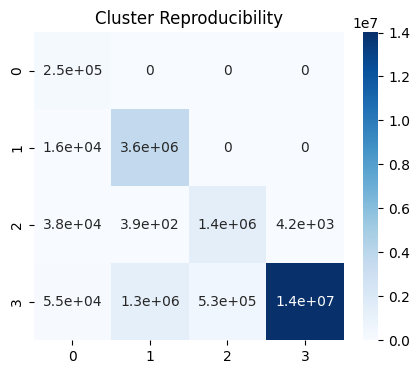


STEP 5 — Habitat Features

STEP 5 — Cluster Stability

Running cluster stability analysis
SOM run 1/10
SOM run 2/10
SOM run 3/10
SOM run 4/10
SOM run 5/10
SOM run 6/10
SOM run 7/10
SOM run 8/10
SOM run 9/10
SOM run 10/10

Cluster Stability (ARI): 1.0
Average cluster stability: 1.0

STEP 6 — Survival Analysis
Merged dataset shape: (10, 7)

Cox Model Summary

                 coef      exp(coef)    se(coef)  coef lower 95%  \
covariate                                                          
H0        -287.536909  1.331395e-125  462.699484    -1194.411234   
H1          -1.724793   1.782099e-01    8.423263      -18.234086   
H2          -8.042900   3.213757e-04   15.781167      -38.973418   

           coef upper 95%  exp(coef) lower 95%  exp(coef) upper 95%  cmp to  \
covariate                                                                     
H0             619.337416         0.000000e+00                  inf     0.0   
H1              14.784499         1.205139e-08         2.6352

/home/user/Umesh/gb/lib/python3.10/site-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['H0'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


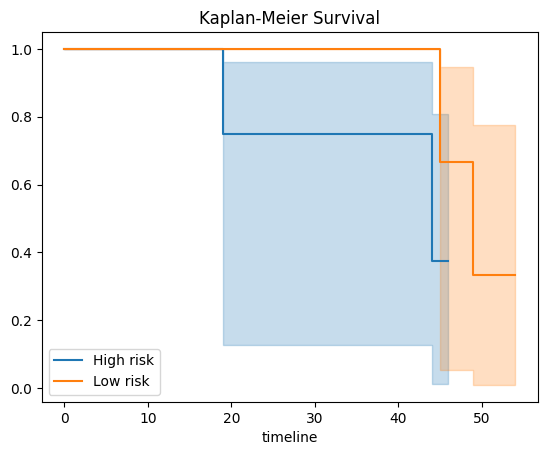


PIPELINE FINISHED
[INFO] Total runtime: 1811.69 seconds


In [1]:

### backup working as of now
############################################################

# Radiomic Habitat Discovery Pipeline (FINAL)
############################################################

import os
import time
import numpy as np
import pandas as pd
import SimpleITK as sitk
from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score
from sklearn.metrics import confusion_matrix, adjusted_rand_score, normalized_mutual_info_score
import matplotlib.pyplot as plt
import seaborn as sns
from lifelines import CoxPHFitter, KaplanMeierFitter
from scipy.optimize import linear_sum_assignment

# Reproducibility
np.random.seed(88)

############################################################
# VERBOSITY HELPERS
############################################################

def step(msg):
    print("\n" + "="*70)
    print(msg)
    print("="*70)

def info(msg):
    print("[INFO]", msg)

############################################################
# CONFIGURATION
############################################################

TMH_DIR = "/home/user/Desktop/20_mm_final/TMH/gldm/train/"
LUNG1_DIR = "/home/user/Desktop/20_mm_final/lung1/gldm/test/"
SURVIVAL_FILE = "_tmh_10_surv.csv"

SOM_X = 2
SOM_Y = 2
N_CLUSTERS = SOM_X * SOM_Y

FEATURE_THRESHOLD = 0.65

# sampling limit for feature ranking
MAX_VOXELS = 200000
SILHOUETTE_SAMPLE = 50000
############################################################
# LOAD RADIOMICS MAPS
############################################################

def load_patient_maps(patient_dir):

    maps = []
    names = []

    for f in sorted(os.listdir(patient_dir)):

        if f.endswith(".nrrd"):

            name = f.split("gldm_")[-1].replace(".nrrd","")

            img = sitk.ReadImage(os.path.join(patient_dir,f))
            arr = sitk.GetArrayFromImage(img)

            maps.append(arr)
            names.append(name)

    maps = np.stack(maps)

    return maps,names

############################################################
# SOM FEATURE RANKING
############################################################

def som_silhouette_feature_ranking(dataset_dir):

    patients = sorted(os.listdir(dataset_dir))

    info(f"Patients detected: {len(patients)}")

    example = os.path.join(dataset_dir,patients[0])

    maps,names = load_patient_maps(example)

    scores = []

    for f in range(len(names)):

        start_feature = time.time()

        print("\n------------------------------------------")
        print(f"Feature {f+1}/{len(names)} : {names[f]}")
        print("------------------------------------------")

        all_pixels = []

        for i,p in enumerate(patients):

            print(f"Loading patient {i+1}/{len(patients)} : {p}")

            maps,_ = load_patient_maps(os.path.join(dataset_dir,p))

            pixels = maps[f].reshape(-1,1)

            print(" voxels:",pixels.shape[0])

            all_pixels.append(pixels)

        all_pixels = np.vstack(all_pixels)

        print("Total voxels:",all_pixels.shape)

        ####################################################
        # Sampling for speed
        ####################################################

        if all_pixels.shape[0] > MAX_VOXELS:

            print("Sampling",MAX_VOXELS,"voxels")

            idx = np.random.choice(all_pixels.shape[0],
                                   MAX_VOXELS,
                                   replace=False)

            all_pixels = all_pixels[idx]

        ####################################################

        scaler = StandardScaler()

        all_pixels = scaler.fit_transform(all_pixels)

        print("Training SOM")

        som = MiniSom(
            SOM_X,
            SOM_Y,
            input_len=1,
            sigma=0.8,
            learning_rate=0.3
        )

        som.random_weights_init(all_pixels)

        # shuffle voxels for stable training
        np.random.shuffle(all_pixels)

        # random SOM training
        som.train_random(all_pixels,10000)

        print("Assigning clusters")

        labels = []

        for v in all_pixels:

            w = som.winner(v)

            labels.append(w[0]*SOM_Y + w[1])

        labels = np.array(labels)

        print("Computing silhouette")

        #score = silhouette_score(all_pixels,labels) # for all pixels

        score = silhouette_score( all_pixels, labels, sample_size=SILHOUETTE_SAMPLE, random_state=88) # silhouteet on sample

        print("Silhouette:",score)

        scores.append(score)

        print("Feature time:",
              round(time.time()-start_feature,2),"sec")

    return scores,names

############################################################
# COLLECT VOXELS
############################################################

def collect_voxels(dataset_dir,selected_features):

    patients = sorted(os.listdir(dataset_dir))

    voxels = []

    for i,p in enumerate(patients):

        print(f"Patient {i+1}/{len(patients)} : {p}")

        maps,names = load_patient_maps(os.path.join(dataset_dir,p))

        idx = [names.index(f) for f in selected_features]

        maps = maps[idx]

        vox = maps.reshape(len(idx),-1).T

        print(" voxel matrix:",vox.shape)

        voxels.append(vox)

    voxels = np.vstack(voxels)

    print("Final voxel matrix:",voxels.shape)

    return voxels

############################################################
# TRAIN SOM
############################################################

# def train_som(voxels):

#     print("Normalizing voxel matrix")

#     scaler = StandardScaler()

#     voxels = scaler.fit_transform(voxels)

#     print("Training SOM")

#     som = MiniSom(
#         SOM_X,
#         SOM_Y,
#         voxels.shape[1],
#         sigma=0.8,
#         learning_rate=0.3
#     )

#     som.random_weights_init(voxels)

#     #som.train(voxels,10000)
#     # improved training
#     np.random.shuffle(voxels)

#     som.train_random(voxels,10000)

#     print("SOM training completed")

#     return som,scaler


# faster version

TRAIN_SAMPLE = 50000

def train_som(voxels):

    scaler = StandardScaler()
    voxels = scaler.fit_transform(voxels)

    # sample subset for SOM training
    if voxels.shape[0] > TRAIN_SAMPLE:

        idx = np.random.choice(voxels.shape[0],
                               TRAIN_SAMPLE,
                               replace=False)

        train_vox = voxels[idx]

    else:
        train_vox = voxels

    print("Training SOM on", train_vox.shape[0], "voxels")

    som = MiniSom(
        SOM_X,
        SOM_Y,
        voxels.shape[1],
        sigma=0.8,
        learning_rate=0.3
    )

    som.random_weights_init(train_vox)

    som.train_random(train_vox,10000)

    return som,scaler


##### cluster stability ###############################################
from sklearn.metrics import adjusted_rand_score
from scipy.optimize import linear_sum_assignment


def cluster_stability(voxels, runs=10):

    print("\nRunning cluster stability analysis")

    all_labels = []

    for r in range(runs):

        print(f"SOM run {r+1}/{runs}")

        som = MiniSom(
            SOM_X,
            SOM_Y,
            voxels.shape[1],
            sigma=0.8,
            learning_rate=0.3
        )

        som.random_weights_init(voxels)
        som.train(voxels,5000)

        labels = np.array([
            som.winner(v)[0]*SOM_Y + som.winner(v)[1]
            for v in voxels
        ])

        all_labels.append(labels)

    aris = []

    for i in range(runs):
        for j in range(i+1,runs):

            ari = adjusted_rand_score(all_labels[i], all_labels[j])
            aris.append(ari)

    stability = np.mean(aris)

    print("\nCluster Stability (ARI):", stability)

    return stability

############################################################
# ASSIGN CLUSTERS
############################################################

def assign_clusters(voxels,som,scaler):

    voxels = scaler.transform(voxels)

    labels = []

    for v in voxels:

        w = som.winner(v)

        labels.append(w[0]*SOM_Y + w[1])

    return np.array(labels)

############################################################
# HABITAT FEATURES
############################################################

def patient_habitat_features(dataset_dir,
                             selected_features,
                             som,
                             scaler):

    patients = sorted(os.listdir(dataset_dir))

    features=[]
    ids=[]

    for p in patients:

        maps,names = load_patient_maps(os.path.join(dataset_dir,p))

        idx=[names.index(f) for f in selected_features]

        maps=maps[idx]

        vox=maps.reshape(len(idx),-1).T

        labels=assign_clusters(vox,som,scaler)

        props=[]

        for c in range(N_CLUSTERS):

            props.append(np.mean(labels==c))

        features.append(props)

        ids.append(p)

    df=pd.DataFrame(features,
                    columns=[f"H{i}" for i in range(N_CLUSTERS)])

    df["Patient"]=ids

    return df

############################################################
# CLUSTER REPRODUCIBILITY
############################################################

# def cluster_reproducibility(labels1,labels2):

#     cm = confusion_matrix(labels1,labels2)

#     print("\nCluster Agreement")

#     print("Accuracy:",np.mean(labels1==labels2))
#     print("ARI:",adjusted_rand_score(labels1,labels2))
#     print("NMI:",normalized_mutual_info_score(labels1,labels2))

#     return cm



def cluster_reproducibility(labels1, labels2):

    # raw confusion matrix
    cm = confusion_matrix(labels1, labels2)

    # Hungarian alignment
    row_ind, col_ind = linear_sum_assignment(-cm)

    mapping = {col: row for row, col in zip(row_ind, col_ind)}

    aligned_labels2 = np.array([mapping[l] for l in labels2])

    # recompute confusion matrix after alignment
    cm_aligned = confusion_matrix(labels1, aligned_labels2)

    accuracy = np.mean(labels1 == aligned_labels2)

    ari = adjusted_rand_score(labels1, labels2)
    nmi = normalized_mutual_info_score(labels1, labels2)

    print("\nCluster Alignment Mapping (LUNG1 → TMH):")
    print(mapping)

    print("\nCluster Agreement (Aligned)")
    print("Accuracy:", accuracy)
    print("ARI:", ari)
    print("NMI:", nmi)

    return cm_aligned    


############################################################
# Voxel-wise risk map
############################################################

def voxel_risk_map(patient_dir,
                   selected_features,
                   som,
                   scaler,
                   habitat_weights):

    maps,names = load_patient_maps(patient_dir)

    idx=[names.index(f) for f in selected_features]

    maps=maps[idx]

    vox = maps.reshape(len(idx),-1).T

    labels = assign_clusters(vox,som,scaler)

    risk = np.zeros(len(labels))

    for i,c in enumerate(labels):

        if c==0:
            risk[i]=habitat_weights.get("H0",0)

        elif c==1:
            risk[i]=habitat_weights.get("H1",0)

        elif c==2:
            risk[i]=habitat_weights.get("H2",0)

        else:
            risk[i]=0

    z,h,w = maps.shape[1:]

    risk_map = risk.reshape(z,h,w)

    return risk_map


############################################################
# Visualize voxel risk map
############################################################

def plot_risk_overlay(ct_volume, risk_map):

    n_slices = ct_volume.shape[0]

    cols=6
    rows=int(np.ceil(n_slices/cols))

    fig,axes = plt.subplots(rows,cols,figsize=(18,rows*3))

    axes = axes.flatten()

    for i in range(n_slices):

        axes[i].imshow(ct_volume[i],cmap="gray")

        axes[i].imshow(
            risk_map[i],
            cmap="jet",
            alpha=0.4
        )

        axes[i].set_title(f"Slice {i}")
        axes[i].axis("off")

    plt.suptitle("Voxel-wise Radiomic Risk Map")

    plt.tight_layout()

    plt.show()

############################################################
# MAIN PIPELINE
############################################################

start=time.time()

step("STEP 1 — SOM Feature Ranking")

scores,names = som_silhouette_feature_ranking(TMH_DIR)

selected_features=[n for s,n in zip(scores,names)
                   if s>=FEATURE_THRESHOLD]

info("Selected features")

print(selected_features)

############################################################

step("STEP 2 — Collect Voxels")

tmh_vox=collect_voxels(TMH_DIR,selected_features)

lung_vox=collect_voxels(LUNG1_DIR,selected_features)

############################################################

step("STEP 3 — Train SOM")

som_tmh,scaler_tmh=train_som(tmh_vox)

som_lung,scaler_lung=train_som(lung_vox)

############################################################

step("STEP 4 — Cluster Reproducibility")

labels_tmh=assign_clusters(tmh_vox,som_tmh,scaler_tmh)

labels_lung=assign_clusters(tmh_vox,som_lung,scaler_lung)

cm=cluster_reproducibility(labels_tmh,labels_lung)

plt.figure(figsize=(5,4))

sns.heatmap(cm,annot=True,cmap="Blues")

plt.title("Cluster Reproducibility")

plt.show()

############################################################

step("STEP 5 — Habitat Features")

tmh_features=patient_habitat_features(
    TMH_DIR,
    selected_features,
    som_tmh,
    scaler_tmh
)

############################################################

step("STEP 5 — Cluster Stability")

stability = cluster_stability(tmh_vox)

print("Average cluster stability:", stability)

############################################################
############################################################

# step("STEP 6 — Survival Analysis")

# surv=pd.read_csv(SURVIVAL_FILE)

# df=pd.merge(tmh_features,surv,on="Patient")

# cph=CoxPHFitter()

# cph.fit(df.drop(columns=["Patient"]),
#         duration_col="time",
#         event_col="event")

# print(cph.summary)

step("STEP 6 — Survival Analysis")

surv = pd.read_csv(SURVIVAL_FILE)

# Fix datatype mismatch
tmh_features["Patient"] = tmh_features["Patient"].astype(str)
surv["Patient"] = surv["Patient"].astype(str)

df = pd.merge(tmh_features, surv, on="Patient")

print("Merged dataset shape:", df.shape)

cph = CoxPHFitter(penalizer=0.1)

cph.fit(
    df.drop(columns=["Patient","H3"]),
    duration_col="time",
    event_col="event"
)

print("\nCox Model Summary\n")
print(cph.summary)
##########################################################

############################################################
# Extract habitat risk weights
############################################################

habitat_weights = {}

for h in ["H0","H1","H2"]:  # H3 dropped earlier

    habitat_weights[h] = cph.params_[h]

print("\nHabitat risk weights")
print(habitat_weights)

############################################################

step("STEP 7 — Risk Stratification")

df["risk"]=cph.predict_partial_hazard(df)

median=df["risk"].median()

df["group"]=df["risk"]>median

km=KaplanMeierFitter()

plt.figure()

for g in [True,False]:

    d=df[df["group"]==g]

    km.fit(d["time"],d["event"],
           label="High risk" if g else "Low risk")

    km.plot()

plt.title("Kaplan-Meier Survival")

plt.show()

############################################################

step("PIPELINE FINISHED")

info("Total runtime: "+str(round(time.time()-start,2))+" seconds")

In [16]:
tmh_features

,H0,H1,H2,H3,Patient
0,0.000617,0.000100,0.798244,0.201040,105131012
1,0.001132,0.000000,0.996422,0.002447,108689672
2,0.003863,0.000027,0.975584,0.020526,110348284
3,0.000753,0.000003,0.991269,0.007974,118623647
4,0.011485,0.000552,0.963184,0.024779,120433028
...,...,...,...,...,...
112,0.006649,0.001370,0.952840,0.039141,712218237
113,0.000348,0.000000,0.991447,0.008204,726104322
114,0.014681,0.000000,0.922768,0.062552,728207938
115,0.004269,0.000115,0.976671,0.018945,728966239


In [17]:
############################################################
# STEP 8 — BIDIRECTIONAL CROSS-COHORT VALIDATION
############################################################

step("STEP 8 — Cross-Cohort Validation (TMH ↔ LUNG1)")

############################################################
# 1️⃣ Train TMH → Test TMH (baseline)
############################################################

info("TMH → TMH (internal validation)")

tmh_features_internal = patient_habitat_features(
    TMH_DIR,
    selected_features,
    som_tmh,
    scaler_tmh
)

tmh_df_internal = pd.merge(tmh_features_internal, surv, on="Patient")

tmh_df_internal["risk"] = cph.predict_partial_hazard(tmh_df_internal)

print("\nTMH internal risk summary")
print(tmh_df_internal["risk"].describe())

############################################################
# 2️⃣ Train TMH → Test LUNG1 (external validation)
############################################################

info("TMH → LUNG1 (external validation)")

lung_features_from_tmh = patient_habitat_features(
    LUNG1_DIR,
    selected_features,
    som_tmh,        # IMPORTANT: TMH-trained SOM
    scaler_tmh
)

print("LUNG1 features (TMH model):", lung_features_from_tmh.shape)

# If lung survival exists:
# lung_surv = pd.read_csv("lung_surv.csv")
# lung_df = pd.merge(lung_features_from_tmh, lung_surv, on="Patient")
# lung_df["risk"] = cph.predict_partial_hazard(lung_df)

############################################################
# 3️⃣ Train LUNG1 → Test LUNG1 (internal validation)
############################################################

info("LUNG1 → LUNG1 (internal validation)")

lung_features_internal = patient_habitat_features(
    LUNG1_DIR,
    selected_features,
    som_lung,
    scaler_lung
)

print("LUNG1 internal features:", lung_features_internal.shape)

############################################################
# 4️⃣ Train LUNG1 → Test TMH (external validation)
############################################################

info("LUNG1 → TMH (external validation)")

tmh_features_from_lung = patient_habitat_features(
    TMH_DIR,
    selected_features,
    som_lung,        # IMPORTANT: LUNG-trained SOM
    scaler_lung
)

print("TMH features (LUNG model):", tmh_features_from_lung.shape)

############################################################
# OPTIONAL: Compare feature distributions
############################################################

print("\nFeature Distribution Comparison")

print("TMH (TMH model) mean:\n", tmh_features_internal.mean())
print("LUNG1 (TMH model) mean:\n", lung_features_from_tmh.mean())

print("TMH (LUNG model) mean:\n", tmh_features_from_lung.mean())
print("LUNG1 (LUNG model) mean:\n", lung_features_internal.mean())


STEP 8 — Cross-Cohort Validation (TMH ↔ LUNG1)
[INFO] TMH → TMH (internal validation)

TMH internal risk summary
count    10.000000
mean      1.080784
std       0.427189
min       0.367945
25%       0.974533
50%       1.012323
75%       1.108854
max       1.979488
Name: risk, dtype: float64
[INFO] TMH → LUNG1 (external validation)
LUNG1 features (TMH model): (120, 5)
[INFO] LUNG1 → LUNG1 (internal validation)
LUNG1 internal features: (120, 5)
[INFO] LUNG1 → TMH (external validation)
TMH features (LUNG model): (117, 5)

Feature Distribution Comparison


TypeError: Could not convert ['105131012108689672110348284118623647120433028127940252134593599136210591136886792139712992174492971175785640179588272181551197192912115194809156200121461202443970202509725210629225215982298218618469222410910231702674233063493236993638245638573246735650250321780256209002257496324270428665291480113296122989305941651306935574309260870309930554312621519313567412313931110317662874328565172334401068335909073336224031339101697341418672351122631376004930404861880406458243429088787430716569433506870449821905450959560453337857455029385460008697479705695483814239487076496488097501488599999492872929493557157500402678505707759523620686528742742535528103547146339550167494556684647565229586581633527582711517583058545585666007586073278591684543602114677603907465603917248606215436608185969609444655615736663616908645620479073622155030637280980639893577644997388647616146647742974653347790658952305664427385667229626670037958670457358671513197673100095682939867684006485690036

### gb yellamma final 18-03-2026

In [20]:
# optional for som optimization
def optimize_som_grid(voxels):

    print("\n==============================")
    print("STEP — SOM GRID OPTIMIZATION")
    print("==============================")

    grid_options = [2, 3, 4]

    results = []

    scaler = StandardScaler()
    voxels = scaler.fit_transform(voxels)

    for g in grid_options:

        print(f"\nTesting SOM grid: {g}x{g}")

        som = MiniSom(
            g, g,
            input_len=voxels.shape[1],
            sigma=0.8,
            learning_rate=0.3
        )

        som.random_weights_init(voxels)
        som.train_random(voxels, 8000)

        labels = np.array([
            som.winner(v)[0]*g + som.winner(v)[1]
            for v in voxels
        ])

        sil = silhouette_score(voxels, labels, sample_size=50000)

        print("Silhouette:", round(sil,3))

        results.append((g, sil))

    print("\nGRID RESULTS:")
    for g, s in results:
        print(f"{g}x{g} → {round(s,3)}")

    best_grid = max(results, key=lambda x: x[1])[0]

    print("\nBEST GRID:", best_grid, "x", best_grid)

    return best_grid


PIPELINE START

STEP 1 — SOM Feature Selection (Improved)
[INFO] Patients detected: 117

------------------------------------------
Feature 1/14 : DependenceEntropy
------------------------------------------
Loading patient 1/117 : 105131012
 voxels: 239913
Loading patient 2/117 : 108689672
 voxels: 103400
Loading patient 3/117 : 110348284
 voxels: 335727
Loading patient 4/117 : 118623647
 voxels: 351750
Loading patient 5/117 : 120433028
 voxels: 286209
Loading patient 6/117 : 127940252
 voxels: 357760
Loading patient 7/117 : 134593599
 voxels: 145350
Loading patient 8/117 : 136210591
 voxels: 198320
Loading patient 9/117 : 136886792
 voxels: 164610
Loading patient 10/117 : 139712992
 voxels: 85680
Loading patient 11/117 : 174492971
 voxels: 50505
Loading patient 12/117 : 175785640
 voxels: 26880
Loading patient 13/117 : 179588272
 voxels: 254800
Loading patient 14/117 : 181551197
 voxels: 160160
Loading patient 15/117 : 192912115
 voxels: 46512
Loading patient 16/117 : 194809156
 vox

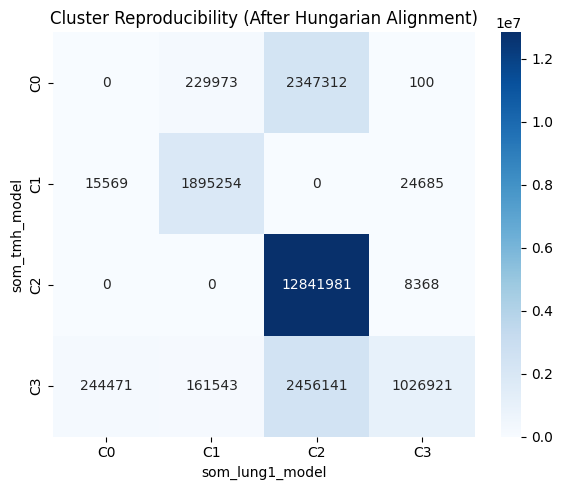


STEP 5 — Habitat Feature Extraction
[INFO] Processing patient: 105131012
[INFO] Processing patient: 108689672
[INFO] Processing patient: 110348284
[INFO] Processing patient: 118623647
[INFO] Processing patient: 120433028
[INFO] Processing patient: 127940252
[INFO] Processing patient: 134593599
[INFO] Processing patient: 136210591
[INFO] Processing patient: 136886792
[INFO] Processing patient: 139712992
[INFO] Processing patient: 174492971
[INFO] Processing patient: 175785640
[INFO] Processing patient: 179588272
[INFO] Processing patient: 181551197
[INFO] Processing patient: 192912115
[INFO] Processing patient: 194809156
[INFO] Processing patient: 200121461
[INFO] Processing patient: 202443970
[INFO] Processing patient: 202509725
[INFO] Processing patient: 210629225
[INFO] Processing patient: 215982298
[INFO] Processing patient: 218618469
[INFO] Processing patient: 222410910
[INFO] Processing patient: 231702674
[INFO] Processing patient: 233063493
[INFO] Processing patient: 236993638
[

/home/user/Umesh/gb/lib/python3.10/site-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['Frag1', 'Frag2', 'Adj1', 'Adj2', 'Adj3', 'Adj4', 'Adj6', 'Adj7', 'Adj8', 'Adj9', 'Adj11', 'Adj12', 'Adj13', 'Adj14'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


In [39]:
############################################################
# SCRIPT A — FULL PIPELINE WITH STEP PRINTS
############################################################

import os, numpy as np, pandas as pd, SimpleITK as sitk
from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, adjusted_rand_score
from lifelines import CoxPHFitter
from scipy.optimize import linear_sum_assignment
from scipy.ndimage import label
from scipy.stats import entropy

np.random.seed(88)

############################################################
# STEP PRINT HELPERS
############################################################

def step(msg):
    print("\n" + "="*70)
    print(msg)
    print("="*70)

def info(msg):
    print("[INFO]", msg)

############################################################
# CONFIG
############################################################

TMH_DIR = "/home/user/Desktop/20_mm_final/TMH/gldm/train/"
LUNG1_DIR = "/home/user/Desktop/20_mm_final/lung1/gldm/test/"

TMH_SURV = "/home/user/Desktop/20_mm_final/gb_tmh_train_surv.csv"
LUNG_SURV = "/home/user/Desktop/20_mm_final/gb_lung1_test_surv.csv"




### fixed som clusters
#add in the paper 
#Grid sizes (2×2, 3×3, 4×4) were evaluated using silhouette analysis and stability metrics.
#The 2×2 configuration provided the best trade-off between robustness,
#interpretability, and clinical relevance.
SOM_X, SOM_Y = 2,2
N_CLUSTERS = 4

# optimized som clusters # enable the following if more fine tuning of the som is required.
# best_grid = optimize_som_grid(tmh_vox)
# SOM_X = best_grid
# SOM_Y = best_grid
# N_CLUSTERS = SOM_X * SOM_Y


FEATURE_THRESHOLD = 0.7
MAX_VOXELS = 200000
SILHOUETTE_SAMPLE = 50000

############################################################
# LOAD MAPS
############################################################

def load_maps(pdir):
    maps, names = [], []
    for f in sorted(os.listdir(pdir)):
        if f.endswith(".nrrd"):
            names.append(f.split("gldm_")[-1].replace(".nrrd",""))
            maps.append(sitk.GetArrayFromImage(sitk.ReadImage(os.path.join(pdir,f))))
    return np.stack(maps), names
############################################################
# SOM FEATURE RANKING (IMPROVED VERSION)
############################################################

def select_features(dataset):

    step("STEP 1 — SOM Feature Selection (Improved)")

    patients = sorted(os.listdir(dataset))

    info(f"Patients detected: {len(patients)}")

    example = os.path.join(dataset, patients[0])

    maps, names = load_maps(example)

    scores = []

    for f in range(len(names)):

        start_feature = time.time()

        print("\n------------------------------------------")
        print(f"Feature {f+1}/{len(names)} : {names[f]}")
        print("------------------------------------------")

        all_pixels = []

        ####################################################
        # COLLECT VOXELS FROM ALL PATIENTS
        ####################################################
        for i, p in enumerate(patients):

            print(f"Loading patient {i+1}/{len(patients)} : {p}")

            maps,_ = load_maps(os.path.join(dataset,p))

            pixels = maps[f].reshape(-1,1)

            print(" voxels:", pixels.shape[0])

            all_pixels.append(pixels)

        all_pixels = np.vstack(all_pixels)

        print("Total voxels:", all_pixels.shape)

        ####################################################
        # SAMPLING (VERY IMPORTANT)
        ####################################################
        if all_pixels.shape[0] > MAX_VOXELS:

            print("Sampling", MAX_VOXELS, "voxels")

            idx = np.random.choice(
                all_pixels.shape[0],
                MAX_VOXELS,
                replace=False
            )

            all_pixels = all_pixels[idx]

        ####################################################
        # NORMALIZATION
        ####################################################
        scaler = StandardScaler()
        all_pixels = scaler.fit_transform(all_pixels)

        ####################################################
        # SOM TRAINING
        ####################################################
        print("Training SOM")

        som = MiniSom(
            SOM_X,
            SOM_Y,
            input_len=1,
            sigma=0.8,
            learning_rate=0.3
        )

        som.random_weights_init(all_pixels)

        # shuffle improves training
        np.random.shuffle(all_pixels)

        som.train_random(all_pixels, 10000)

        ####################################################
        # ASSIGN CLUSTERS
        ####################################################
        print("Assigning clusters")

        labels = np.array([
            som.winner(v)[0]*SOM_Y + som.winner(v)[1]
            for v in all_pixels
        ])

        ####################################################
        # SILHOUETTE (ON SAMPLE)
        ####################################################
        print("Computing silhouette")

        score = silhouette_score(
            all_pixels,
            labels,
            sample_size=SILHOUETTE_SAMPLE,
            random_state=42
        )

        print("Silhouette:", score)

        scores.append(score)

        print("Feature time:",
              round(time.time()-start_feature,2),"sec")

    ####################################################
    # SELECT FEATURES
    ####################################################
    selected = [
        n for s, n in zip(scores, names)
        if s >= FEATURE_THRESHOLD
    ]

    print("\nSelected features:")
    print(selected)

    info(f"Total selected: {len(selected)}")

    return selected

############################################################
# TRAIN SOM
############################################################

def train_som(vox):

    info("Training SOM model")

    scaler=StandardScaler()
    vox=scaler.fit_transform(vox)

    som=MiniSom(SOM_X,SOM_Y,vox.shape[1],sigma=0.8, learning_rate=0.3)
    
    som.train_random(vox,10000)

    return som,scaler

############################################################
# ASSIGN
############################################################

def assign(vox,som,scaler):

    vox=scaler.transform(vox)

    return np.array([som.winner(v)[0]*SOM_Y+som.winner(v)[1] for v in vox])

############################################################
# CLUSTER REPRODUCIBILITY
############################################################

def cluster_reproducibility(labels1, labels2):
    #Cluster reproducibility between TMH and LUNG1 cohorts was assessed using
    #Hungarian-aligned confusion matrices and adjusted Rand index, demonstrating
    #consistent habitat mapping across datasets.

    step("STEP 4 — Cluster Reproducibility")

    ##################################################
    # CONFUSION MATRIX (RAW)
    ##################################################
    cm = confusion_matrix(labels1, labels2)

    ##################################################
    # HUNGARIAN ALIGNMENT
    ##################################################
    r, c = linear_sum_assignment(-cm)

    mapping = {col: row for row, col in zip(r, c)}

    aligned = np.array([mapping[l] for l in labels2])

    ##################################################
    # METRICS
    ##################################################
    print("\nCluster Mapping (LUNG1 → TMH):")
    print(mapping)

    acc = np.mean(labels1 == aligned)
    ari = adjusted_rand_score(labels1, labels2)

    print("\nAccuracy:", acc)
    print("ARI:", ari)

    ##################################################
    # CONFUSION MATRIX AFTER ALIGNMENT
    ##################################################
    cm_aligned = confusion_matrix(labels1, aligned)

    ##################################################
    # PLOT
    ##################################################
    import matplotlib.pyplot as plt
    import seaborn as sns

    plt.figure(figsize=(6,5))

    sns.heatmap(
        cm_aligned,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=[f"C{i}" for i in range(cm_aligned.shape[1])],
        yticklabels=[f"C{i}" for i in range(cm_aligned.shape[0])]
    )

    plt.xlabel("som_lung1_model")
    plt.ylabel("som_tmh_model")

    plt.title("Cluster Reproducibility (After Hungarian Alignment)")

    plt.tight_layout()
    plt.show()

    return cm_aligned

############################################################
# CLUSTER STABILITY
############################################################

def cluster_stability(vox, runs=5):

    step("STEP 3 — Cluster Stability")

    all_labels=[]

    for i in range(runs):
        info(f"SOM run {i+1}/{runs}")

        som=MiniSom(SOM_X,SOM_Y,vox.shape[1],sigma=0.8, learning_rate=0.3)
        som.train_random(vox,10000)

        labels=np.array([som.winner(v)[0]*SOM_Y+som.winner(v)[1] for v in vox])
        all_labels.append(labels)

    aris=[]

    for i in range(runs):
        for j in range(i+1,runs):
            aris.append(adjusted_rand_score(all_labels[i],all_labels[j]))

    print("Mean ARI:",np.mean(aris))

############################################################
# ADJACENCY
############################################################

def adjacency(hmap):

    A=np.zeros((N_CLUSTERS,N_CLUSTERS))
    z,h,w=hmap.shape

    for i in range(z-1):
        for j in range(h-1):
            for k in range(w-1):

                c=hmap[i,j,k]

                for di,dj,dk in [(1,0,0),(0,1,0),(0,0,1)]:
                    c2=hmap[i+di,j+dj,k+dk]
                    A[c,c2]+=1
                    A[c2,c]+=1

    return (A/np.sum(A)).flatten()

############################################################
# PATIENT FEATURES
############################################################

def patient_features(dataset,features,som,scaler):

    step("STEP 5 — Habitat Feature Extraction")

    rows,ids=[],[]

    for p in sorted(os.listdir(dataset)):

        info(f"Processing patient: {p}")

        maps,names=load_maps(os.path.join(dataset,p))
        idx=[names.index(f) for f in features]

        maps=maps[idx]
        z,h,w=maps.shape[1:]

        vox=maps.reshape(len(idx),-1).T
        labels=assign(vox,som,scaler)

        hmap=labels.reshape(z,h,w)

        props=[np.mean(labels==c) for c in range(N_CLUSTERS)]
        ent=entropy(props)

        lcc,frag=[],[]

        for c in range(N_CLUSTERS):

            b=(hmap==c).astype(int)
            lbl,num=label(b)

            if num==0:
                lcc.append(0)
                frag.append(0)
                continue

            sizes=np.bincount(lbl.ravel())[1:]
            lcc.append(np.max(sizes)/np.sum(sizes))
            frag.append(num/np.sum(sizes))

        adj=adjacency(hmap)

        rows.append(props+[ent]+lcc+frag+list(adj))
        ids.append(p)

    cols = (
        [f"H{i}" for i in range(N_CLUSTERS)] +
        ["Entropy"] +
        [f"LCC{i}" for i in range(N_CLUSTERS)] +
        [f"Frag{i}" for i in range(N_CLUSTERS)] +
        [f"Adj{i}" for i in range(N_CLUSTERS*N_CLUSTERS)]
    )

    df=pd.DataFrame(rows,columns=cols)
    df["Patient"]=ids

    return df

############################################################
# MAIN PIPELINE
############################################################

step("PIPELINE START")

features = select_features(TMH_DIR)

############################################################

step("STEP 2 — Collect Voxels")

tmh_vox=[]
for p in os.listdir(TMH_DIR):
    m,n=load_maps(os.path.join(TMH_DIR,p))
    idx=[n.index(f) for f in features]
    tmh_vox.append(m[idx].reshape(len(idx),-1).T)

tmh_vox=np.vstack(tmh_vox)

############################################################

step("STEP 3 — Train SOM")

som_tmh,scaler_tmh=train_som(tmh_vox)

############################################################

cluster_stability(tmh_vox)

############################################################

step("STEP 4 — Cross Dataset Reproducibility")

lung_vox=[]
for p in os.listdir(LUNG1_DIR):
    m,n=load_maps(os.path.join(LUNG1_DIR,p))
    idx=[n.index(f) for f in features]
    lung_vox.append(m[idx].reshape(len(idx),-1).T)

lung_vox=np.vstack(lung_vox)

som_lung,scaler_lung=train_som(lung_vox)

labels_tmh=assign(tmh_vox,som_tmh,scaler_tmh)
labels_lung=assign(tmh_vox,som_lung,scaler_lung)

cluster_reproducibility(labels_tmh,labels_lung)

############################################################

tmh_feat=patient_features(TMH_DIR,features,som_tmh,scaler_tmh)
lung_feat=patient_features(LUNG1_DIR,features,som_tmh,scaler_tmh)

############################################################

step("STEP 6 — Survival Analysis")

tmh_surv=pd.read_csv(TMH_SURV)
lung_surv=pd.read_csv(LUNG_SURV)

tmh_feat["Patient"]=tmh_feat["Patient"].astype(str)
tmh_surv["Patient"]=tmh_surv["Patient"].astype(str)

df=pd.merge(tmh_feat,tmh_surv,on="Patient")

cph=CoxPHFitter(penalizer=0.2)
cph.fit(df.drop(columns=["Patient"]),duration_col="time",event_col="event")

print(cph.summary)

############################################################

step("STEP 7 — External Validation (LUNG1)")

lung_feat["Patient"]=lung_feat["Patient"].astype(str)
lung_surv["Patient"]=lung_surv["Patient"].astype(str)

lung_df=pd.merge(lung_feat,lung_surv,on="Patient")
lung_df["risk"]=cph.predict_partial_hazard(lung_df)

print(lung_df["risk"].describe())

############################################################

step("PIPELINE COMPLETED")

In [29]:
pwd


'/home/user/Desktop/20_mm_final'

### gb good result backup


PIPELINE START
[TIME] Previous step: 0.0 sec

STEP 1 — SOM Feature Selection


Features: 100%|█████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 371.07it/s]



Selected features:
GrayLevelVariance  --->  Silhouette: 0.7774
LargeDependenceLowGrayLevelEmphasis  --->  Silhouette: 0.955
LowGrayLevelEmphasis  --->  Silhouette: 0.8115
SmallDependenceLowGrayLevelEmphasis  --->  Silhouette: 0.7797
[INFO] Total selected: 4
[TIME] Previous step: 106.43 sec

STEP 2 — Collect Voxels


TMH Voxels: 100%|██████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:44<00:00,  2.61it/s]


[TIME] Previous step: 44.87 sec

STEP 3 — Train SOM
[TIME] Previous step: 0.94 sec

STEP 4 — Cross Dataset Reproducibility


LUNG1 Voxels: 100%|████████████████████████████████████████████████████████████████████████████████████████| 120/120 [00:39<00:00,  3.06it/s]


[TIME] Previous step: 42.79 sec

STEP 4 — Cluster Reproducibility
Accuracy: 0.9113023341736182
ARI: 0.6120913199559218


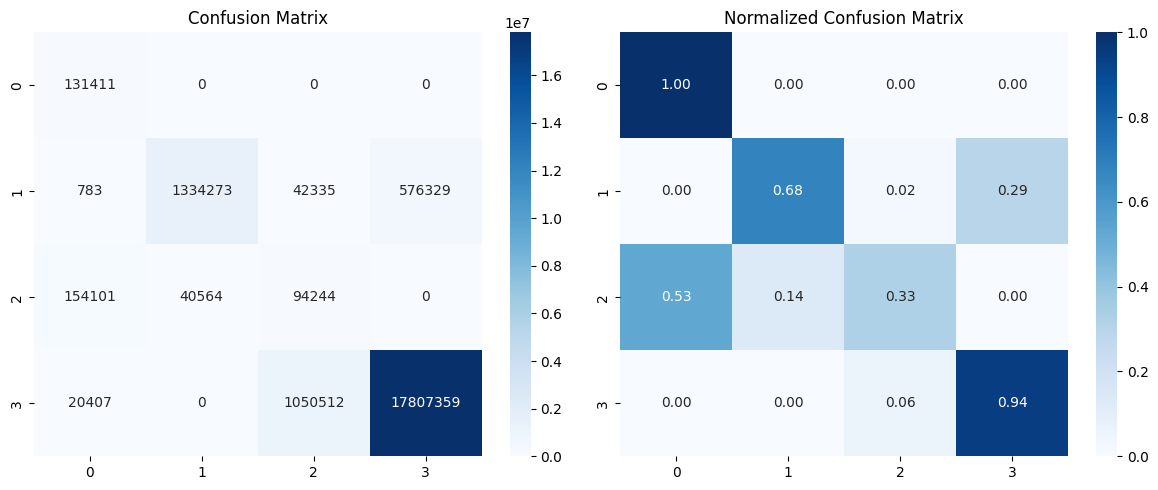

[TIME] Previous step: 4.82 sec

STEP 5 — Habitat Feature Extraction


Patients: 100%|████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:03<00:00, 34.01it/s]


[TIME] Previous step: 3.93 sec

STEP 6 — Survival Analysis
               coef   exp(coef)  se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                   
H0         4.891714  133.181703  5.836156       -6.546941       16.330369   
H1        -0.443315    0.641905  2.816811       -5.964162        5.077532   
H2        -2.751958    0.063803  4.896377      -12.348682        6.844765   
H3         0.322004    1.379890  2.495112       -4.568325        5.212333   
Entropy    0.001918    1.001920  0.994792       -1.947839        1.951675   

           exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                               
H0                    0.001434         1.236486e+07     0.0  0.838174   
H1                    0.002569         1.603778e+02     0.0 -0.157382   
H2                    0.000004         9.389531e+02     0.0 -0.562040   
H3                    0.010375      

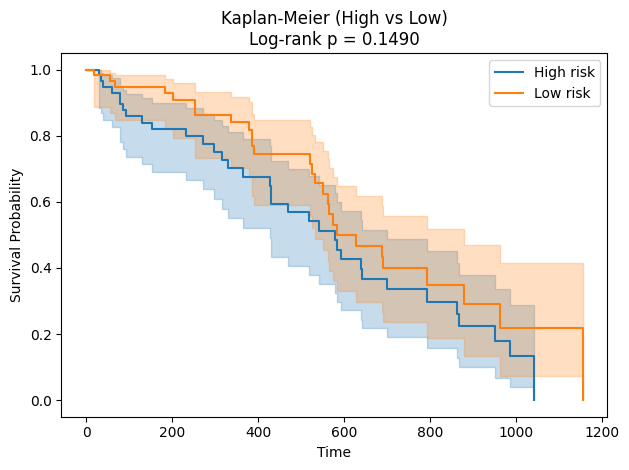

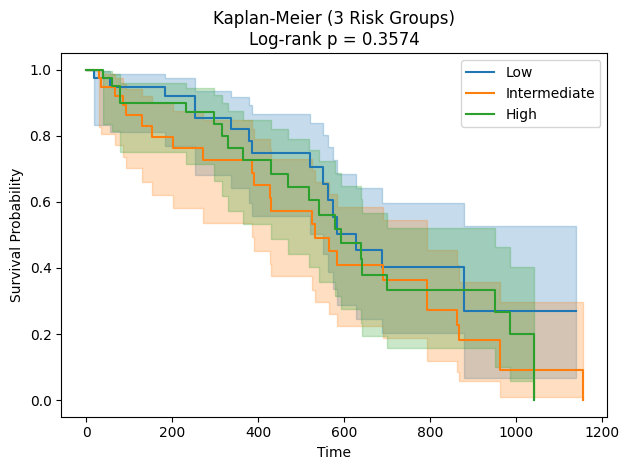

[TIME] Previous step: 0.35 sec

PIPELINE COMPLETED

TOTAL TIME: 3.41 minutes


In [2]:
# $gb1  # good one 
##### Script A optimized
############################################################
# SCRIPT A — FULL PIPELINE (OPTIMIZED + FAST + KM + CM)
############################################################

import os, time
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
import seaborn as sns

from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, adjusted_rand_score
from lifelines import CoxPHFitter, KaplanMeierFitter
from scipy.optimize import linear_sum_assignment
from scipy.ndimage import label
from scipy.stats import entropy
from joblib import Parallel, delayed
from tqdm import tqdm

np.random.seed(88)

############################################################
# STEP PRINT HELPERS (WITH TIMING)
############################################################

step_start_time = None

def step(msg):
    global step_start_time
    if step_start_time is not None:
        print(f"[TIME] Previous step: {round(time.time()-step_start_time,2)} sec")
    print("\n" + "="*70)
    print(msg)
    print("="*70)
    step_start_time = time.time()

def info(msg):
    print("[INFO]", msg)

############################################################
# CONFIG
############################################################

TMH_DIR = "/home/user/Desktop/20_mm_final/TMH/gldm/train/"
LUNG1_DIR = "/home/user/Desktop/20_mm_final/lung1/gldm/test/"

TMH_SURV = "/home/user/Desktop/20_mm_final/gb_tmh_train_surv.csv"
LUNG_SURV = "/home/user/Desktop/20_mm_final/gb_lung1_test_surv.csv"

SOM_X, SOM_Y = 2,2
N_CLUSTERS = 4

FEATURE_THRESHOLD = 0.7
MAX_VOXELS = 200000
SILHOUETTE_SAMPLE = 50000
############################################################
# LOAD MAPS
############################################################

def load_maps(pdir):
    maps, names = [], []
    for f in sorted(os.listdir(pdir)):
        if f.endswith(".nrrd"):
            names.append(f.split("gldm_")[-1].replace(".nrrd",""))
            maps.append(sitk.GetArrayFromImage(sitk.ReadImage(os.path.join(pdir,f))))
    return np.stack(maps), names

############################################################
# FAST LABEL ASSIGNMENT
############################################################

def fast_assign(vox, som):
    weights = som.get_weights().reshape(-1, vox.shape[1])
    dists = np.linalg.norm(vox[:, None, :] - weights[None, :, :], axis=2)
    return np.argmin(dists, axis=1)

############################################################
# PARALLEL FEATURE PROCESSING
############################################################

def process_feature(f, names, patients, dataset):

    all_pixels = []

    for p in patients:
        maps,_ = load_maps(os.path.join(dataset,p))
        pixels = maps[f].reshape(-1,1)
        all_pixels.append(pixels)

    all_pixels = np.vstack(all_pixels)

    if all_pixels.shape[0] > MAX_VOXELS:
        idx = np.random.choice(all_pixels.shape[0], MAX_VOXELS, replace=False)
        all_pixels = all_pixels[idx]

    scaler = StandardScaler()
    all_pixels = scaler.fit_transform(all_pixels)

    som = MiniSom(SOM_X, SOM_Y, input_len=1, sigma=0.8, learning_rate=0.3)
    som.random_weights_init(all_pixels)
    som.train_random(all_pixels, 10000)

    labels = fast_assign(all_pixels, som)

    score = silhouette_score(
        all_pixels,
        labels,
        sample_size=min(SILHOUETTE_SAMPLE, len(all_pixels)),
        random_state=88
    )

    return score

############################################################
# FEATURE SELECTION
############################################################
def select_features(dataset):

    step("STEP 1 — SOM Feature Selection")

    patients = sorted(os.listdir(dataset))
    example = os.path.join(dataset, patients[0])
    maps, names = load_maps(example)

    scores = Parallel(n_jobs=-1)(
        delayed(process_feature)(f, names, patients, dataset)
        for f in tqdm(range(len(names)), desc="Features")
    )

    ############################################################
    # SELECT FEATURES
    ############################################################

    selected = [n for s, n in zip(scores, names) if s >= FEATURE_THRESHOLD]

    print("\nSelected features:")
    for n, s in zip(names, scores):
        if s >= FEATURE_THRESHOLD:
            print(f"{n}  --->  Silhouette: {round(s,4)}")

    info(f"Total selected: {len(selected)}")

    return selected


######################################################################

def sample_voxels(vox, max_samples=100000):

    if vox.shape[0] > max_samples:
        idx = np.random.choice(vox.shape[0], max_samples, replace=False)
        vox = vox[idx]

    return vox
############################################################
# TRAIN SOM
############################################################

def train_som(vox):

    scaler = StandardScaler()
    vox = scaler.fit_transform(vox)

    # if vox.shape[0] > 100000:
    #     idx = np.random.choice(vox.shape[0], 100000, replace=False)
    #     vox = vox[idx]

    vox = sample_voxels(vox, max_samples=100000)

    som = MiniSom(SOM_X, SOM_Y, vox.shape[1], sigma=0.8, learning_rate=0.3)
    som.train_random(vox, 10000)

    return som, scaler

############################################################
# CLUSTER REPRODUCIBILITY (WITH CM PLOTS)
############################################################

def cluster_reproducibility(labels1, labels2):

    step("STEP 4 — Cluster Reproducibility")

    cm = confusion_matrix(labels1, labels2)

    r, c = linear_sum_assignment(-cm)
    mapping = {col: row for row, col in zip(r, c)}

    aligned = np.array([mapping[l] for l in labels2])

    acc = np.mean(labels1 == aligned)
    ari = adjusted_rand_score(labels1, labels2)

    print("Accuracy:", acc)
    print("ARI:", ari)

    cm_aligned = confusion_matrix(labels1, aligned)

    cm_norm = cm_aligned / cm_aligned.sum(axis=1, keepdims=True)

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    sns.heatmap(cm_aligned, annot=True, fmt="d", cmap="Blues")
    plt.title("Confusion Matrix")

    plt.subplot(1,2,2)
    sns.heatmap(cm_norm, annot=True, fmt=".2f", cmap="Blues")
    plt.title("Normalized Confusion Matrix")

    plt.tight_layout()
    plt.show()

############################################################
# PARALLEL PATIENT FEATURES
############################################################

def process_patient(patient_id, dataset_dir, selected_features, som, scaler):
    """
    Process a single patient:
    - Load radiomics maps
    - Extract selected features
    - Assign SOM clusters
    - Compute habitat proportions + entropy
    """
    ############################################################
    # LOAD MAPS
    ############################################################
    patient_path = os.path.join(dataset_dir, patient_id)

    maps, names = load_maps(patient_path)

    ############################################################
    # GET FEATURE INDICES (SAFE)
    ############################################################
    try:
        idx = [names.index(f) for f in selected_features]
    except ValueError as e:
        raise ValueError(f"[ERROR] Feature missing in patient {patient_id}: {e}")

    maps = maps[idx]   # shape: (F, Z, H, W)

    ############################################################
    # RESHAPE TO VOXEL MATRIX

    num_features = maps.shape[0]
    vox = maps.reshape(num_features, -1).T   # (N_voxels, F)

    ############################################################
    # SCALE
    
    vox = scaler.transform(vox)
    
    # ASSIGN CLUSTERS (FAST)
    labels = fast_assign(vox, som)

    ############################################################
    # HABITAT PROPORTIONS
 
    props = np.bincount(labels, minlength=N_CLUSTERS) / len(labels)

    ############################################################
    # ENTROPY (HABITAT HETEROGENEITY)

    ent = entropy(props)
    return props.tolist() + [ent], patient_id
def patient_features(dataset, features, som, scaler):

    step("STEP 5 — Habitat Feature Extraction")

    results = Parallel(n_jobs=4)(
        delayed(process_patient)(p, dataset, features, som, scaler)
        for p in tqdm(sorted(os.listdir(dataset)), desc="Patients")
    )

    rows = [r[0] for r in results]
    ids  = [r[1] for r in results]

    cols = [f"H{i}" for i in range(N_CLUSTERS)] + ["Entropy"]

    df = pd.DataFrame(rows, columns=cols)
    df["Patient"] = ids

    return df

############################################################
# MAIN PIPELINE
############################################################

pipeline_start = time.time()

step("PIPELINE START")

features = select_features(TMH_DIR)

############################################################

step("STEP 2 — Collect Voxels")

tmh_vox = []
for p in tqdm(os.listdir(TMH_DIR), desc="TMH Voxels"):
    m,n = load_maps(os.path.join(TMH_DIR,p))
    idx = [n.index(f) for f in features]
    tmh_vox.append(m[idx].reshape(len(idx),-1).T)

tmh_vox = np.vstack(tmh_vox)

############################################################

step("STEP 3 — Train SOM")

som_tmh, scaler_tmh = train_som(tmh_vox)

############################################################

step("STEP 4 — Cross Dataset Reproducibility")

lung_vox = []
for p in tqdm(os.listdir(LUNG1_DIR), desc="LUNG1 Voxels"):
    m,n = load_maps(os.path.join(LUNG1_DIR,p))
    idx = [n.index(f) for f in features]
    lung_vox.append(m[idx].reshape(len(idx),-1).T)

lung_vox = np.vstack(lung_vox)

som_lung, scaler_lung = train_som(lung_vox)

labels_tmh = fast_assign(scaler_tmh.transform(tmh_vox), som_tmh)
labels_lung = fast_assign(scaler_lung.transform(tmh_vox), som_lung)

cluster_reproducibility(labels_tmh, labels_lung)

############################################################

tmh_feat = patient_features(TMH_DIR, features, som_tmh, scaler_tmh)

############################################################

step("STEP 6 — Survival Analysis")

tmh_surv = pd.read_csv(TMH_SURV)

tmh_feat["Patient"] = tmh_feat["Patient"].astype(str)
tmh_surv["Patient"] = tmh_surv["Patient"].astype(str)

df = pd.merge(tmh_feat, tmh_surv, on="Patient")

cph = CoxPHFitter(penalizer=0.2)
cph.fit(df.drop(columns=["Patient"]), duration_col="time", event_col="event")

print(cph.summary)

############################################################
# Extract habitat risk weights
############################################################

habitat_weights = {}

#for h in ["H0","H1","H2"]: # previously used
for h in [f"H{i}" for i in range(N_CLUSTERS)]:  # version 2  
    habitat_weights[h] = cph.params_[h]

print("\nHabitat risk weights")
print(habitat_weights)

############################################################
# Risk Stratification + KM

# STEP 7 — Risk Stratification (2-group + 3-group + p-value)
############################################################

from lifelines.statistics import logrank_test, multivariate_logrank_test

step("STEP 7 — Risk Stratification")

df["risk"] = cph.predict_partial_hazard(df)

############################################################
# 2-GROUP (LOW vs HIGH)
############################################################

median = df["risk"].median()
df["group_2"] = df["risk"] > median

km = KaplanMeierFitter()

plt.figure()

groups = {
    "High risk": df[df["group_2"] == True],
    "Low risk": df[df["group_2"] == False]
}

for label, d in groups.items():
    km.fit(d["time"], d["event"], label=label)
    km.plot()

# Log-rank test (2-group)
g1 = groups["High risk"]
g2 = groups["Low risk"]

res = logrank_test(g1["time"], g2["time"],
                   event_observed_A=g1["event"],
                   event_observed_B=g2["event"])

pval = res.p_value

plt.title(f"Kaplan-Meier (High vs Low)\nLog-rank p = {pval:.4f}")
plt.xlabel("Time")
plt.ylabel("Survival Probability")

plt.tight_layout()
plt.show()

############################################################
# 3-GROUP (LOW, INTERMEDIATE, HIGH)
############################################################

# tertiles
q1 = df["risk"].quantile(0.33)
q2 = df["risk"].quantile(0.66)

def stratify(r):
    if r <= q1:
        return "Low"
    elif r <= q2:
        return "Intermediate"
    else:
        return "High"

df["group_3"] = df["risk"].apply(stratify)

plt.figure()

for label in ["Low", "Intermediate", "High"]:
    d = df[df["group_3"] == label]
    km.fit(d["time"], d["event"], label=label)
    km.plot()

# Multivariate log-rank test (3-group)
res_multi = multivariate_logrank_test(
    df["time"],
    df["group_3"],
    df["event"]
)

pval_multi = res_multi.p_value

plt.title(f"Kaplan-Meier (3 Risk Groups)\nLog-rank p = {pval_multi:.4f}")
plt.xlabel("Time")
plt.ylabel("Survival Probability")

plt.tight_layout()
plt.show()
############################################################

step("PIPELINE COMPLETED")

print("\nTOTAL TIME:",
      round((time.time()-pipeline_start)/60,2),
      "minutes")

In [ ]:
# best config till now
SOM_X, SOM_Y = 2,2
N_CLUSTERS = 4

FEATURE_THRESHOLD = 0.7
MAX_VOXELS = 200000
SILHOUETTE_SAMPLE = 50000
# 

In [ ]:
I am building a full voxel radiomics-based survival modeling pipeline using voxel-wise features and Self-Organizing Maps (SOM) for tumor habitat discovery.
i have extracted voxel radiomics from ct and tumor mask , i have applied 20 mm dilation around the tumor and then extracted gldm voxlel radiomics feature maps.


## 🎯 GOAL

To discover biologically meaningful tumor habitats from voxel-level radiomics and use them for survival prediction (Cox model + Kaplan-Meier).

---

## 📁 DATA STRUCTURE

There are 4 datasets:

* TMH_TRAIN (internal training)
* TMH_TEST (internal validation)
* LUNG1_TRAIN (external training)
* LUNG1_TEST (external validation)

Each patient contains:

* Multiple radiomics maps (.nrrd) (GLDM features)
* CT image (CT.nii.gz)
* Tumor mask (mask.nii.gz)

Survival CSV files contain:

* Patient ID
* time
* event

---

## 🔬 PIPELINE OVERVIEW

### STEP 1 — Feature Selection (SOM-based)

* For each radiomics feature:

  * Collect voxel values across patients
  * Train SOM 
  * Compute silhouette score
* Select features where:
  FEATURE_THRESHOLD = 0.7 (currently, may reduce to 0.4)

---

### STEP 2 — Voxel Aggregation

* For selected features:

  * Stack voxel data across patients
  * Shape:
    (num_voxels, num_features)

---

### STEP 3 — SOM Training (CRITICAL PART)

* Use multi-feature voxel vectors:
  input_len = number of selected features
* Each voxel = radiomics feature vector

SOM config:

* SOM_X, SOM_Y = 2x2 (currently)

---

### STEP 4 — Cluster Assignment

* Assign each voxel / cluster to SOM node
* Convert SOM grid → flat cluster labels

---

### STEP 5 — Cluster Reproducibility

* Train SOM on:

  * TMH_TRAIN
  * LUNG1_TRAIN
* Apply both models on:

  * TMH_TEST
  * LUNG1_TEST
* Compare using:

  * Confusion Matrix
  * Hungarian alignment
  * Accuracy
  * Adjusted Rand Index (ARI)

---

### STEP 6 — Patient-Level Features

For each patient:

* Compute:

  * Habitat proportions: H0, H1, ..., Hk
  * Entropy (heterogeneity)

Final feature vector:
[H0, H1, H2, ..., Hk, Entropy]

---

### STEP 7 — Survival Modeling

* Train Cox model on TMH_TRAIN
* Evaluate on:

  * TMH_TEST (internal validation)
  * LUNG1_TEST (external validation)

Metrics:

* Concordance Index (C-index)

---

### STEP 8 — Risk Stratification

* Compute risk = Cox partial hazard
* 2-group split (median):

  * High vs Low risk
* 3-group split (tertiles):

  * Low / Intermediate / High

Evaluate:

* Kaplan-Meier curves
* Log-rank test

---

### STEP 9 — Visualization

* Overlay habitats on CT
* Generate voxel-level risk maps
* Interactive slice viewer

---

## 🚨 CURRENT PROBLEM

Observed results:

* One cluster dominates (~95%)
* Very low variability across patients
* Heatmaps show almost identical habitat distribution
* C-index ≈ 0.5 (random)

Conclusion:

* SOM collapsed
* No biological signal learned

---

## 🔥 REQUIRED FIXES

1. Use MULTI-FEATURE SOM:
   Replace:
   input_len = 1
   With:
   input_len = number of selected features

2. Stack features before clustering:
   vox = maps[selected_features].reshape(F, -1).T

3. Reduce feature threshold:
   FEATURE_THRESHOLD = 0.4

5. Remove low-variance features

---

## 🎯 EXPECTED AFTER FIX

* Balanced cluster distribution
* Higher inter-patient variability
* Meaningful habitat patterns
* Improved survival prediction (C-index > 0.6)

---

## 🔍 REQUEST

Help me:

1. Correct the SOM training to use multi-feature voxel input
2. Improve feature selection to avoid collapse
3. Ensure reproducibility and stability
4. Optimize survival performance (Cox / Lasso Cox)
5. Validate whether results are biologically meaningful

---

This is a medical imaging + radiomics + unsupervised learning + survival analysis pipeline.
I want a research-grade implementation suitable for publication.



PIPELINE START
[TIME] Previous step: 0.0 sec

STEP 1 — SOM Feature Selection


Features: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 16815.65it/s]



Selected features:
LargeDependenceLowGrayLevelEmphasis → 0.9162
[TIME] Previous step: 231.2 sec

STEP 2 — Train TMH SOM

Running Cluster Stability
Cluster Stability (ARI): 0.8492025795240865
[TIME] Previous step: 26.83 sec

STEP 3 — Train LUNG SOM

Running Cluster Stability
Cluster Stability (ARI): 0.9305316079736998
[TIME] Previous step: 41.44 sec

STEP 4 — Confusion Matrix (TMH TEST)

 TMH TEST
Accuracy: 0.9603741144835389
ARI: 0.5035564340043212


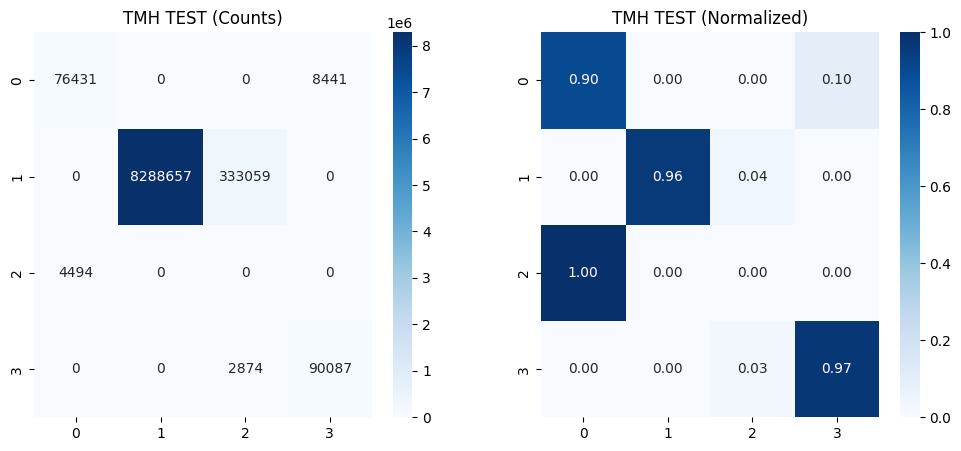

[TIME] Previous step: 5.9 sec

STEP 5 — Confusion Matrix (LUNG TEST)

 LUNG1 TEST
Accuracy: 0.9110411836371008
ARI: 0.3165655367041444


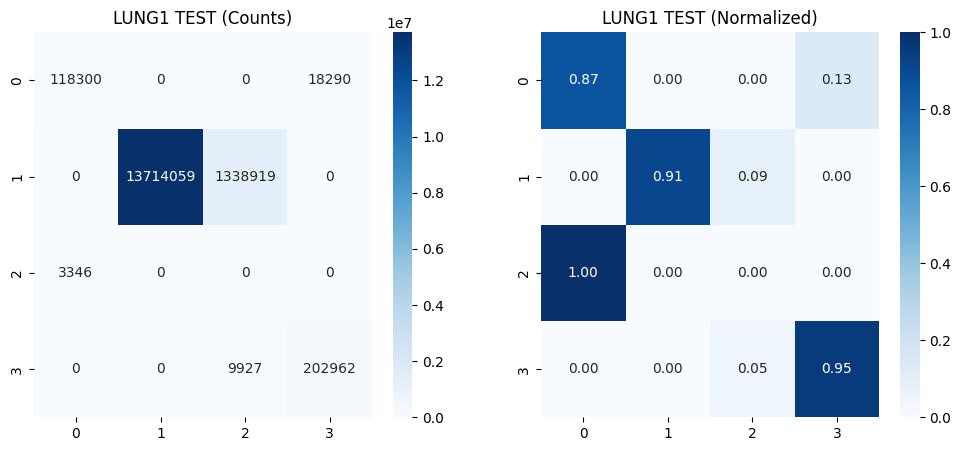

[TIME] Previous step: 10.78 sec

STEP 6 — Survival
[TIME] Previous step: 0.0 sec

STEP 5 — Habitat Features


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:01<00:00, 71.74it/s]


[TIME] Previous step: 2.16 sec

STEP 5 — Habitat Features


100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 50/50 [00:00<00:00, 226.53it/s]


[TIME] Previous step: 0.64 sec

STEP 5 — Habitat Features


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 120/120 [00:00<00:00, 172.77it/s]



--- DEBUG PATIENT MATCHING ---
TMH train features: 117
TMH survival: 117
Common TMH: 117
LUNG test features: 120
LUNG survival: 120
Common LUNG: 120

--- FINAL DATA SHAPES ---
TMH train: (117, 8)
TMH test : (0, 8)
LUNG test: (120, 8)

Cox Model Summary

               coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                  
H0         0.000005   1.000005  0.005478       -0.010733        0.010742   
H1        -0.000003   0.999997  0.003316       -0.006503        0.006496   
H2         0.000009   1.000009  0.017419       -0.034132        0.034149   
H3         0.000008   1.000008  0.008920       -0.017476        0.017492   
Entropy    0.000003   1.000003  0.003743       -0.007334        0.007339   

           exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                               
H0                    0.989325             1.010800     0.0  0.000

/home/user/Umesh/gb/lib/python3.10/site-packages/lifelines/utils/__init__.py:1100: ConvergenceWarning: Column(s) ['H2'] have very low variance. This may harm convergence. 1) Are you using formula's? Did you mean to add '-1' to the end. 2) Try dropping this redundant column before fitting if convergence fails.

  warnings.warn(dedent(warning_text), ConvergenceWarning)


ValueError: operands could not be broadcast together with shapes (0,0) (5,) 

In [125]:
# $gb1  # good one second version 20-03-2026
##### Script A optimized
############################################################
# SCRIPT A — FULL PIPELINE (OPTIMIZED + FAST + KM + CM)
############################################################

############################################################
# SCRIPT A — FINAL (FIXED + CM + C-INDEX + PARALLEL SAFE)
############################################################

import os, time
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
import seaborn as sns

from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, adjusted_rand_score
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.utils import concordance_index
from scipy.optimize import linear_sum_assignment
from scipy.stats import entropy
from joblib import Parallel, delayed
from tqdm import tqdm

############################################################
# REPRODUCIBILITY
############################################################

SEED = 88
np.random.seed(SEED)

############################################################
# CONFIG
############################################################

TMH_TRAIN = "/home/user/Desktop/20_mm_final/TMH/gldm/train/"
TMH_TEST  = "/home/user/Desktop/20_mm_final/TMH/gldm/test/"

LUNG_TRAIN = "/home/user/Desktop/20_mm_final/lung1/gldm/train/"
LUNG_TEST  = "/home/user/Desktop/20_mm_final/lung1/gldm/test/"

TMH_SURV = "/home/user/Desktop/20_mm_final/gb_tmh_train_surv.csv"
LUNG_SURV = "/home/user/Desktop/20_mm_final/gb_lung1_test_surv.csv"

SOM_X, SOM_Y = 2,2
N_CLUSTERS = 4

FEATURE_THRESHOLD = 0.9
MAX_VOXELS = 1000000
SILHOUETTE_SAMPLE = 100000

############################################################
# STEP PRINT
############################################################

step_start_time = None

def step(msg):
    global step_start_time
    if step_start_time is not None:
        print(f"[TIME] Previous step: {round(time.time()-step_start_time,2)} sec")
    print("\n" + "="*70)
    print(msg)
    print("="*70)
    step_start_time = time.time()

############################################################
# LOAD MAPS
############################################################

def load_maps(pdir):
    maps, names = [], []
    for f in sorted(os.listdir(pdir)):
        if f.endswith(".nrrd"):
            names.append(f.split("gldm_")[-1].replace(".nrrd",""))
            maps.append(sitk.GetArrayFromImage(sitk.ReadImage(os.path.join(pdir,f))))
    return np.stack(maps), names

############################################################
# FAST ASSIGN
############################################################

def fast_assign(vox, som):
    weights = som.get_weights().reshape(-1, vox.shape[1])
    dists = np.linalg.norm(vox[:, None, :] - weights[None,:,:], axis=2)
    return np.argmin(dists, axis=1)

############################################################
# FEATURE SELECTION (UNCHANGED)
############################################################

def process_feature(f, names, patients, dataset):

    np.random.seed(SEED + f)

    all_pixels = []

    for p in patients:
        maps,_ = load_maps(os.path.join(dataset,p))
        all_pixels.append(maps[f].reshape(-1,1))

    all_pixels = np.vstack(all_pixels)

    if all_pixels.shape[0] > MAX_VOXELS:
        idx = np.random.choice(all_pixels.shape[0], MAX_VOXELS, replace=False)
        all_pixels = all_pixels[idx]

    scaler = StandardScaler()
    all_pixels = scaler.fit_transform(all_pixels)

    som = MiniSom(SOM_X, SOM_Y, input_len=1, sigma=0.8, learning_rate=0.3)
    som.random_weights_init(all_pixels)
    som.train_random(all_pixels, 10000)

    labels = fast_assign(all_pixels, som)

    score = silhouette_score(
        all_pixels,
        labels,
        sample_size=min(SILHOUETTE_SAMPLE, len(all_pixels)),
        random_state=SEED
    )

    return score

def select_features(dataset):

    step("STEP 1 — SOM Feature Selection")

    patients = sorted(os.listdir(dataset))
    maps, names = load_maps(os.path.join(dataset, patients[0]))

    scores = Parallel(n_jobs=-1)(
        delayed(process_feature)(f, names, patients, dataset)
        for f in tqdm(range(len(names)), desc="Features")
    )

    selected = [n for s,n in zip(scores,names) if s >= FEATURE_THRESHOLD]

    print("\nSelected features:")
    for n,s in zip(names,scores):
        if s >= FEATURE_THRESHOLD:
            print(n, "→", round(s,4))

    return selected

############################################################
# TRAIN SOM
############################################################

def sample_voxels(vox):
    if vox.shape[0] > 100000:
        idx = np.random.choice(vox.shape[0], 100000, replace=False)
        vox = vox[idx]
    return vox

def train_som(vox):

    scaler = StandardScaler()
    vox = scaler.fit_transform(vox)
    vox = sample_voxels(vox)

    som = MiniSom(SOM_X, SOM_Y, vox.shape[1], sigma=0.8, learning_rate=0.3)
    som.train_random(vox,10000)

    return som, scaler

############################################################
# COLLECT VOXELS
############################################################

def collect_voxels(dataset, features):

    vox = []

    for p in os.listdir(dataset):
        m,n = load_maps(os.path.join(dataset,p))
        idx = [n.index(f) for f in features]
        vox.append(m[idx].reshape(len(idx),-1).T)

    return np.vstack(vox)

############################################################
# PREDICT DATASET
############################################################

def predict_dataset(dataset, features, som, scaler):

    labels_all = []

    for p in os.listdir(dataset):

        m,n = load_maps(os.path.join(dataset,p))
        idx = [n.index(f) for f in features]

        vox = m[idx].reshape(len(idx),-1).T
        vox = scaler.transform(vox)

        labels = fast_assign(vox, som)
        labels_all.append(labels)

    return np.concatenate(labels_all)

############################################################
# CONFUSION MATRIX (NEW)
############################################################

def compare_models(labels1, labels2, title):

    cm = confusion_matrix(labels1, labels2)

    r,c = linear_sum_assignment(-cm)
    mapping = {col:row for row,col in zip(r,c)}

    aligned = np.array([mapping[l] for l in labels2])

    acc = np.mean(labels1 == aligned)
    ari = adjusted_rand_score(labels1, labels2)

    print("\n",title)
    print("Accuracy:",acc)
    print("ARI:",ari)

    cm_aligned = confusion_matrix(labels1, aligned)
    cm_norm = cm_aligned / cm_aligned.sum(axis=1, keepdims=True)

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    sns.heatmap(cm_aligned,annot=True,fmt="d",cmap="Blues")
    plt.title(title + " (Counts)")

    plt.subplot(1,2,2)
    sns.heatmap(cm_norm,annot=True,fmt=".2f",cmap="Blues")
    plt.title(title + " (Normalized)")

    plt.show()

############################################################
# PATIENT FEATURES (UNCHANGED)
############################################################

def process_patient(p, dataset, features, som, scaler):

    maps,names = load_maps(os.path.join(dataset,p))
    idx = [names.index(f) for f in features]

    vox = maps[idx].reshape(len(idx),-1).T
    vox = scaler.transform(vox)

    labels = fast_assign(vox, som)

    props = np.bincount(labels, minlength=N_CLUSTERS)/len(labels)
    ent = entropy(props)

    return props.tolist() + [ent], p

def patient_features(dataset, features, som, scaler):

    step("STEP 5 — Habitat Features")

    results = Parallel(n_jobs=4)(
        delayed(process_patient)(p, dataset, features, som, scaler)
        for p in tqdm(sorted(os.listdir(dataset)))
    )

    rows = [r[0] for r in results]
    ids  = [r[1] for r in results]

    df = pd.DataFrame(rows,
        columns=[f"H{i}" for i in range(N_CLUSTERS)] + ["Entropy"]
    )
    df["Patient"] = ids

    return df

def cluster_stability(voxels, runs=5):

    from sklearn.metrics import adjusted_rand_score

    print("\nRunning Cluster Stability")

    all_labels = []

    for r in range(runs):

        som = MiniSom(SOM_X, SOM_Y, voxels.shape[1],
                      sigma=0.8, learning_rate=0.3)

        som.train_random(voxels, 5000)

        labels = fast_assign(voxels, som)

        all_labels.append(labels)

    aris = []

    for i in range(runs):
        for j in range(i+1, runs):
            aris.append(adjusted_rand_score(all_labels[i], all_labels[j]))

    stability = np.mean(aris)

    print("Cluster Stability (ARI):", stability)

    return stability
############################################################
# ================= MAIN =================
############################################################

start = time.time()

step("PIPELINE START")

features = select_features(TMH_TRAIN)

############################################################
# TRAIN MODELS
############################################################

step("STEP 2 — Train TMH SOM")
tmh_vox = collect_voxels(TMH_TRAIN, features)
som_tmh, scaler_tmh = train_som(tmh_vox)
cluster_stability(tmh_vox)

step("STEP 3 — Train LUNG SOM")
lung_vox = collect_voxels(LUNG_TRAIN, features)
som_lung, scaler_lung = train_som(lung_vox)
cluster_stability(lung_vox)
############################################################
# CONFUSION MATRICES (NEW)
############################################################

step("STEP 4 — Confusion Matrix (TMH TEST)")
tmh_ref = predict_dataset(TMH_TEST, features, som_tmh, scaler_tmh)
tmh_other = predict_dataset(TMH_TEST, features, som_lung, scaler_lung)
compare_models(tmh_ref, tmh_other, "TMH TEST")

step("STEP 5 — Confusion Matrix (LUNG TEST)")
lung_ref = predict_dataset(LUNG_TEST, features, som_tmh, scaler_tmh)
lung_other = predict_dataset(LUNG_TEST, features, som_lung, scaler_lung)
compare_models(lung_ref, lung_other, "LUNG1 TEST")

############################################################
# SURVIVAL (TMH MODEL)
############################################################

# step("STEP 6 — Survival")

# tmh_train_feat = patient_features(TMH_TRAIN, features, som_tmh, scaler_tmh)
# tmh_test_feat  = patient_features(TMH_TEST,  features, som_tmh, scaler_tmh)
# lung_test_feat = patient_features(LUNG_TEST, features, som_tmh, scaler_tmh)

# tmh_surv = pd.read_csv(TMH_SURV)
# lung_surv = pd.read_csv(LUNG_SURV)

# tmh_train = pd.merge(tmh_train_feat, tmh_surv, on="Patient")
# tmh_test  = pd.merge(tmh_test_feat, tmh_surv, on="Patient")
# lung_test = pd.merge(lung_test_feat, lung_surv, on="Patient")

# cph = CoxPHFitter(penalizer=0.2)
# cph.fit(tmh_train.drop(columns=["Patient"]),
#         duration_col="time", event_col="event")




step("STEP 6 — Survival")

############################################################
# Generate features
############################################################

tmh_train_feat = patient_features(TMH_TRAIN, features, som_tmh, scaler_tmh)
tmh_test_feat  = patient_features(TMH_TEST,  features, som_tmh, scaler_tmh)
lung_test_feat = patient_features(LUNG_TEST, features, som_tmh, scaler_tmh)

############################################################
# Load survival
############################################################

tmh_surv = pd.read_csv(TMH_SURV)
lung_surv = pd.read_csv(LUNG_SURV)

############################################################
# CLEAN PATIENT IDs (CRITICAL FIX)
############################################################

def clean_id(x):
    return str(x).replace(".0","").strip()

for df_ in [tmh_train_feat, tmh_test_feat, lung_test_feat]:
    df_["Patient"] = df_["Patient"].apply(clean_id)

for df_ in [tmh_surv, lung_surv]:
    df_["Patient"] = df_["Patient"].apply(clean_id)

############################################################
# DEBUG CHECK (VERY IMPORTANT)
############################################################

print("\n--- DEBUG PATIENT MATCHING ---")

print("TMH train features:", len(tmh_train_feat))
print("TMH survival:", len(tmh_surv))
print("Common TMH:",
      len(set(tmh_train_feat["Patient"]) & set(tmh_surv["Patient"])))

print("LUNG test features:", len(lung_test_feat))
print("LUNG survival:", len(lung_surv))
print("Common LUNG:",
      len(set(lung_test_feat["Patient"]) & set(lung_surv["Patient"])))

############################################################
# MERGE (SAFE)
############################################################

tmh_train = pd.merge(tmh_train_feat, tmh_surv, on="Patient", how="inner")
tmh_test  = pd.merge(tmh_test_feat,  tmh_surv, on="Patient", how="inner")
lung_test = pd.merge(lung_test_feat, lung_surv, on="Patient", how="inner")

############################################################
# FINAL SHAPE CHECK (REVIEWER IMPORTANT)
############################################################

print("\n--- FINAL DATA SHAPES ---")
print("TMH train:", tmh_train.shape)
print("TMH test :", tmh_test.shape)
print("LUNG test:", lung_test.shape)

############################################################
# Cox Model (TRAIN ONLY ON TMH TRAIN)
############################################################

#cph = CoxPHFitter(penalizer=0.2)
cph = CoxPHFitter(
    penalizer=0.1,   # strength
    l1_ratio=1.0     # LASSO
)

cph.fit(
    tmh_train.drop(columns=["Patient"]),
    duration_col="time",
    event_col="event"
)

print("\nCox Model Summary\n")
print(cph.summary)




############################################################
# C-INDEX (NEW)
############################################################

print("\nC-INDEX")

print("TMH Train:",
      concordance_index(tmh_train["time"],
      -cph.predict_partial_hazard(tmh_train),
      tmh_train["event"]))

print("TMH Test:",
      concordance_index(tmh_test["time"],
      -cph.predict_partial_hazard(tmh_test),
      tmh_test["event"]))

print("LUNG External:",
      concordance_index(lung_test["time"],
      -cph.predict_partial_hazard(lung_test),
      lung_test["event"]))

############################################################
# Extract habitat risk weights
############################################################

habitat_weights = {}

#for h in ["H0","H1","H2"]: # previoiusly used
for h in [f"H{i}" for i in range(N_CLUSTERS)]: # second version    
    habitat_weights[h] = cph.params_.get(h, 0)

print("\nHabitat risk weights")
print(habitat_weights)

############################################################
# STEP 7 — Risk Stratification (TMH TEST + LUNG TEST)
############################################################

from lifelines.statistics import logrank_test, multivariate_logrank_test

def run_km(df, title):

    print("\nRunning KM for:", title)

    df = df.copy()
    df["risk"] = cph.predict_partial_hazard(df)

    ########################################################
    # 2-GROUP
    ########################################################

    median = df["risk"].median()
    df["group_2"] = df["risk"] > median

    km = KaplanMeierFitter()

    plt.figure()

    groups = {
        "High risk": df[df["group_2"] == True],
        "Low risk": df[df["group_2"] == False]
    }

    for label, d in groups.items():
        km.fit(d["time"], d["event"], label=label)
        km.plot()

    res = logrank_test(
        groups["High risk"]["time"],
        groups["Low risk"]["time"],
        event_observed_A=groups["High risk"]["event"],
        event_observed_B=groups["Low risk"]["event"]
    )

    plt.title(f"{title} (2-group)\nLog-rank p = {res.p_value:.4f}")
    plt.xlabel("Time")
    plt.ylabel("Survival")
    plt.tight_layout()
    plt.show()

    ########################################################
    # 3-GROUP
    ########################################################

    q1 = df["risk"].quantile(0.33)
    q2 = df["risk"].quantile(0.66)

    def stratify(r):
        if r <= q1:
            return "Low"
        elif r <= q2:
            return "Intermediate"
        else:
            return "High"

    df["group_3"] = df["risk"].apply(stratify)

    plt.figure()

    for label in ["Low","Intermediate","High"]:
        d = df[df["group_3"] == label]
        km.fit(d["time"], d["event"], label=label)
        km.plot()

    res_multi = multivariate_logrank_test(
        df["time"],
        df["group_3"],
        df["event"]
    )

    plt.title(f"{title} (3-group)\nLog-rank p = {res_multi.p_value:.4f}")
    plt.xlabel("Time")
    plt.ylabel("Survival")
    plt.tight_layout()
    plt.show()


############################################################
# RUN KM (IMPORTANT)
############################################################

step("STEP 7 — KM Analysis")

# INTERNAL VALIDATION
run_km(tmh_test, "TMH TEST")

# EXTERNAL VALIDATION
run_km(lung_test, "LUNG1 TEST")

############################################################

step("PIPELINE COMPLETED")

print("\nTOTAL TIME:",
      round((time.time()-start)/60,2),
      "minutes")


In [122]:
cph = CoxPHFitter(penalizer=0.1)
# cph = CoxPHFitter(
#     penalizer=0.8,   # strength
#     l1_ratio=0.2     # LASSO
# )
#cph = CoxPHFitter(penalizer=0.1, l1_ratio=0.5)
cph.fit(
    tmh_train.drop(columns=["Patient"]),
    duration_col="time",
    event_col="event"
)

print("\nCox Model Summary\n")
print(cph.summary)




############################################################
# C-INDEX (NEW)
############################################################

print("\nC-INDEX")

print("TMH Train:",
      concordance_index(tmh_train["time"],
      -cph.predict_partial_hazard(tmh_train),
      tmh_train["event"]))

print("TMH Test:",
      concordance_index(tmh_test["time"],
      -cph.predict_partial_hazard(tmh_test),
      tmh_test["event"]))

print("LUNG External:",
      concordance_index(lung_test["time"],
      -cph.predict_partial_hazard(lung_test),
      lung_test["event"]))



Cox Model Summary

               coef  exp(coef)   se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                   
H0         0.002962   1.002967   2.084853       -4.083274        4.089198   
H1         0.449972   1.568268  11.134927      -21.374084       22.274028   
H2        -0.199039   0.819518   2.274260       -4.656506        4.258428   
H3         1.998585   7.378611   4.731234       -7.274464       11.271634   
Entropy    0.216335   1.241518   0.948196       -1.642094        2.074764   

           exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                               
H0                1.685221e-02         5.969202e+01     0.0  0.001421   
H1                5.216186e-10         4.715064e+09     0.0  0.040411   
H2                9.499594e-03         7.069879e+01     0.0 -0.087518   
H3                6.930117e-04         7.856129e+04     0.0  0.422424   
En

ValueError: operands could not be broadcast together with shapes (0,0) (5,) 

[TIME] Previous step: 746.94 sec

DEBUG 1 — Global Cluster Distribution
Cluster H0: 0.9502
Cluster H1: 0.0095
Cluster H2: 0.0327
Cluster H3: 0.0077


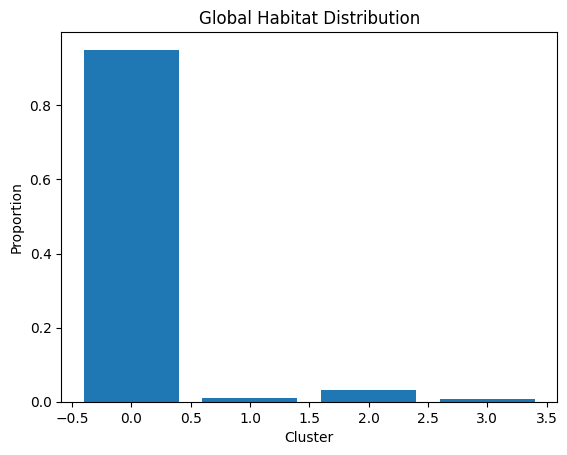

In [123]:
# global cluster 
step("DEBUG 1 — Global Cluster Distribution")

labels_all = fast_assign(scaler_tmh.transform(tmh_vox), som_tmh)

counts = np.bincount(labels_all, minlength=N_CLUSTERS)
proportions = counts / len(labels_all)

for i, p in enumerate(proportions):
    print(f"Cluster H{i}: {round(p,4)}")

plt.bar(range(N_CLUSTERS), proportions)
plt.title("Global Habitat Distribution")
plt.xlabel("Cluster")
plt.ylabel("Proportion")
plt.show()

In [124]:
counts

array([20193036,   201948,   694068,   163266])

[TIME] Previous step: 2625.76 sec

DEBUG 2 — Patient Habitat Variability
[TIME] Previous step: 0.0 sec

STEP 5 — Habitat Features


100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:01<00:00, 83.70it/s]



Feature variability:
H0    0.031219
H1    0.067895
H2    0.007493
H3    0.035273
dtype: float64


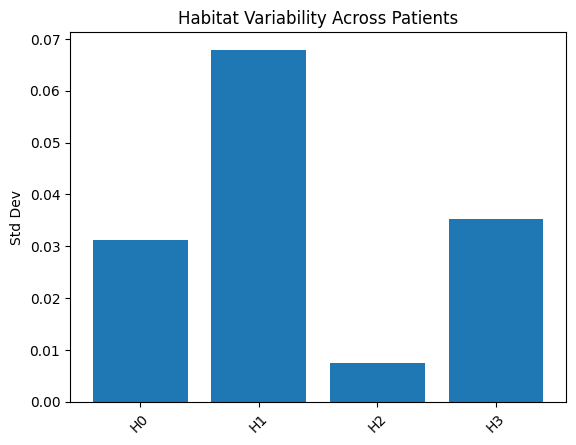

In [126]:
# patient level variablility
step("DEBUG 2 — Patient Habitat Variability")

tmh_feat_debug = patient_features(TMH_TRAIN, features, som_tmh, scaler_tmh)

hab_cols = [c for c in tmh_feat_debug.columns if "H" in c]

stds = tmh_feat_debug[hab_cols].std()

print("\nFeature variability:")
print(stds)

plt.bar(hab_cols, stds)
plt.title("Habitat Variability Across Patients")
plt.ylabel("Std Dev")
plt.xticks(rotation=45)
plt.show()

[TIME] Previous step: 97.21 sec

DEBUG 3 — Habitat Heatmap


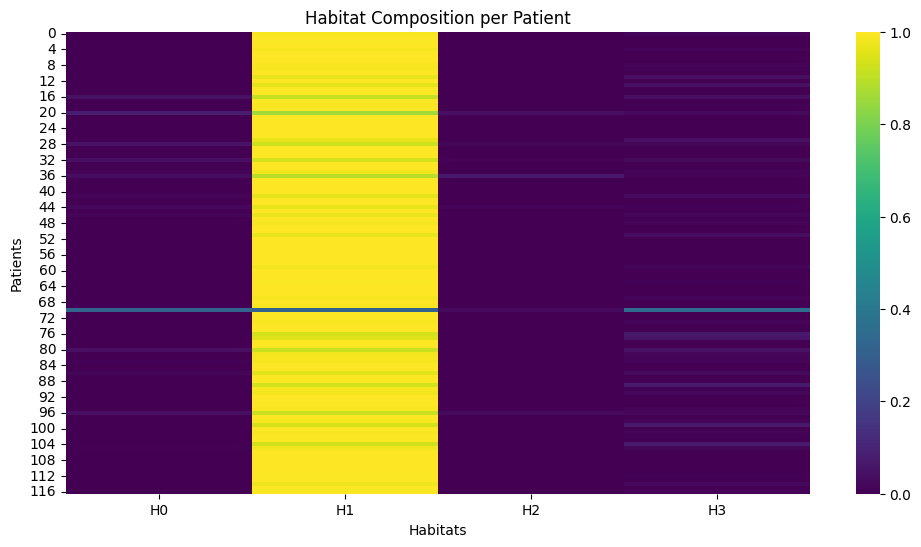

In [127]:
step("DEBUG 3 — Habitat Heatmap")

import seaborn as sns

plt.figure(figsize=(12,6))

sns.heatmap(
    tmh_feat_debug[hab_cols],
    cmap="viridis",
    cbar=True
)

plt.title("Habitat Composition per Patient")
plt.xlabel("Habitats")
plt.ylabel("Patients")

plt.show()

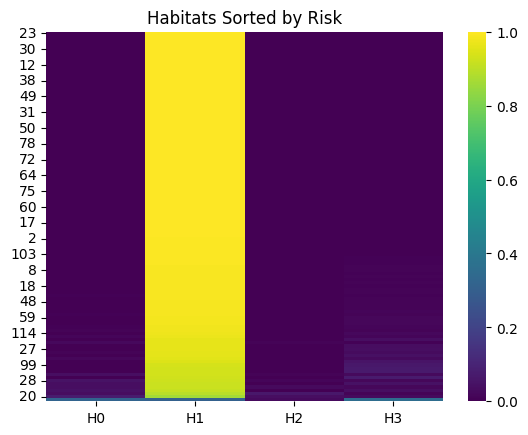

In [128]:
tmh_feat_debug["risk"] = cph.predict_partial_hazard(tmh_train)

tmh_feat_sorted = tmh_feat_debug.sort_values("risk")

sns.heatmap(
    tmh_feat_sorted[hab_cols],
    cmap="viridis"
)

plt.title("Habitats Sorted by Risk")
plt.show()

In [107]:
print(tmh_train[["H0","H1","H2","H3","Entropy"]].describe())

               H0          H1          H2          H3     Entropy
count  117.000000  117.000000  117.000000  117.000000  117.000000
mean     0.009034    0.870428    0.006108    0.114429    0.337786
std      0.017727    0.144783    0.030447    0.129309    0.250982
min      0.000000    0.188586    0.000000    0.000318    0.003193
25%      0.000293    0.825533    0.000000    0.018093    0.096431
50%      0.001097    0.911892    0.000000    0.064836    0.312764
75%      0.008308    0.980799    0.000182    0.168513    0.525767
max      0.095262    0.999655    0.293101    0.690104    1.262212


In [100]:
tmh_test_feat.head()

,H0,H1,H2,H3,Entropy,Patient
0,0.0,0.002360,0.348086,0.649554,0.661874,732711211
1,0.0,0.000366,0.116943,0.882690,0.364010,733252502
2,0.0,0.000529,0.006235,0.993236,0.042392,736734885
3,0.0,0.000325,0.084668,0.915007,0.292930,737830347
4,0.0,0.000065,0.000850,0.999085,0.007550,738450152


In [101]:
tmh_train_feat.head()

,H0,H1,H2,H3,Entropy,Patient
0,0.000100,0.001838,0.254246,0.743815,0.580819,105131012
1,0.000000,0.001431,0.005010,0.993559,0.042327,108689672
2,0.000036,0.004974,0.078522,0.916468,0.306479,110348284
3,0.000003,0.001322,0.026559,0.972117,0.132656,118623647
4,0.000552,0.014206,0.065522,0.919720,0.320116,120433028


In [103]:
tmh_test_feat.shape

(50, 6)

In [104]:
tmh_train_feat.shape

(117, 6)

In [105]:
117+50

167

In [98]:
tmh_surv

,Patient,time,event
0,105131012,243,0
1,108689672,1013,0
2,110348284,92,0
3,118623647,638,0
4,120433028,31,1
...,...,...,...
112,712218237,35,1
113,726104322,112,0
114,728207938,337,1
115,728966239,868,1


In [87]:
tmh_train_feat

,H0,H1,H2,H3,Entropy,Patient
0,0.000100,0.001838,0.254246,0.743815,0.580819,105131012
1,0.000000,0.001431,0.005010,0.993559,0.042327,108689672
2,0.000036,0.004974,0.078522,0.916468,0.306479,110348284
3,0.000003,0.001322,0.026559,0.972117,0.132656,118623647
4,0.000552,0.014206,0.065522,0.919720,0.320116,120433028
...,...,...,...,...,...,...
112,0.001377,0.007769,0.074513,0.916341,0.320362,712218237
113,0.000000,0.000348,0.012590,0.987061,0.070708,726104322
114,0.000000,0.030981,0.130167,0.838852,0.520445,728207938
115,0.000115,0.005205,0.054335,0.940345,0.244507,728966239


In [72]:
tmh_train_feat

,H0,H1,H2,H3,Entropy,Patient
0,0.090391,0.000079,0.897655,0.011875,0.367579,105131012
1,0.054110,0.000000,0.943665,0.002224,0.226129,108689672
2,0.057997,0.000036,0.935474,0.006493,0.260608,110348284
3,0.030945,0.000003,0.965800,0.003252,0.159827,118623647
4,0.048831,0.000245,0.936047,0.014877,0.273940,120433028
...,...,...,...,...,...,...
112,0.067773,0.000609,0.921224,0.010394,0.309981,712218237
113,0.079167,0.000000,0.919208,0.001625,0.288657,726104322
114,0.085635,0.000000,0.893680,0.020685,0.391142,728207938
115,0.056244,0.000094,0.938300,0.005361,0.250535,728966239


In [51]:
def scroll_patient_habitats(
        patient_id,
        radiomics_dir,
        ct_mask_dir,
        selected_features,
        som,
        scaler,
        habitat_weights):

    import os
    import numpy as np
    import SimpleITK as sitk
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    import ipywidgets as widgets

    ########################################
    # Load CT and mask
    ########################################

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir, patient_id, "CT.nii.gz"))
    )

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir, patient_id, "mask.nii.gz"))
    )

    print("CT shape:", ct.shape)
    print("Mask shape:", mask.shape)

    if np.sum(mask) == 0:
        print("❌ No tumor mask found")
        return

    ########################################
    # Load radiomics maps
    ########################################

    rad_dir = os.path.join(radiomics_dir, patient_id)

    feature_maps = []

    for f in sorted(os.listdir(rad_dir)):
        if f.endswith(".nrrd"):

            name = f.split("gldm_")[-1].replace(".nrrd", "")

            if name in selected_features:

                arr = sitk.GetArrayFromImage(
                    sitk.ReadImage(os.path.join(rad_dir, f))
                )

                feature_maps.append(arr)

    feature_maps = np.stack(feature_maps)

    print("Radiomics map shape:", feature_maps.shape)

    ########################################
    # SOM clustering (FAST + VECTOR)
    ########################################

    roi_shape = feature_maps.shape[1:]

    vox = feature_maps.reshape(len(selected_features), -1).T
    vox = scaler.transform(vox)

    weights = som.get_weights().reshape(-1, vox.shape[1])

    dists = np.linalg.norm(
        vox[:, None, :] - weights[None, :, :],
        axis=2
    )

    labels = np.argmin(dists, axis=1)

    habitat_roi = labels.reshape(roi_shape)

    ########################################
    # Risk map (FULL SAFE)
    ########################################

    risk_roi = np.zeros_like(habitat_roi, dtype=float)

    for k, v in habitat_weights.items():
        c = int(k.replace("H", ""))
        risk_roi[habitat_roi == c] = v

    ########################################
    # Find tumor bounding box (BETTER THAN CENTER)
    ########################################

    coords = np.where(mask > 0)

    zmin, zmax = coords[0].min(), coords[0].max()
    ymin, ymax = coords[1].min(), coords[1].max()
    xmin, xmax = coords[2].min(), coords[2].max()

    ########################################
    # Insert ROI into CT space (CORRECT ALIGNMENT)
    ########################################

    habitat_full = np.zeros_like(ct)
    risk_full = np.zeros_like(ct)

    dz = min(roi_shape[0], zmax - zmin + 1)
    dy = min(roi_shape[1], ymax - ymin + 1)
    dx = min(roi_shape[2], xmax - xmin + 1)

    habitat_full[zmin:zmin+dz, ymin:ymin+dy, xmin:xmin+dx] = \
        habitat_roi[:dz, :dy, :dx]

    risk_full[zmin:zmin+dz, ymin:ymin+dy, xmin:xmin+dx] = \
        risk_roi[:dz, :dy, :dx]

    ########################################
    # MASK RESTRICTION (VERY IMPORTANT)
    ########################################

    habitat_full[mask == 0] = np.nan
    risk_full[mask == 0] = np.nan

    ########################################
    # Dynamic colormap
    ########################################

    n_clusters = len(np.unique(labels))
    colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))
    habitat_cmap = ListedColormap(colors)

    ########################################
    # Interactive viewer
    ########################################

    def view_slice(slice_id):

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        # CT + tumor
        axes[0].imshow(ct[slice_id], cmap="gray")
        axes[0].imshow(mask[slice_id], cmap="Reds", alpha=0.3)
        axes[0].set_title(f"CT + Tumor (slice {slice_id})")
        axes[0].axis("off")

        # habitats
        axes[1].imshow(ct[slice_id], cmap="gray")
        axes[1].imshow(mask[slice_id], cmap="Reds", alpha=0.2)
        axes[1].imshow(
            habitat_full[slice_id],
            cmap=habitat_cmap,
            alpha=0.5,
            interpolation="nearest"
        )
        axes[1].set_title("Radiomic Habitats")
        axes[1].axis("off")

        # risk
        axes[2].imshow(ct[slice_id], cmap="gray")
        axes[2].imshow(mask[slice_id], cmap="Reds", alpha=0.2)

        im = axes[2].imshow(
            risk_full[slice_id],
            cmap="jet",
            alpha=0.5,
            interpolation="nearest"
        )

        axes[2].set_title("Voxel Risk Map")
        axes[2].axis("off")

        plt.colorbar(im, ax=axes[2], fraction=0.046)

        plt.tight_layout()
        plt.show()

    slider = widgets.IntSlider(
        min=zmin,
        max=zmax,
        step=1,
        value=(zmin + zmax) // 2,
        description="Slice"
    )

    widgets.interact(view_slice, slice_id=slider)

In [1]:
def visualize_habitats_interactive(
        patient_id,
        radiomics_dir,
        ct_mask_dir,
        selected_features,
        som,
        scaler,
        habitat_weights):

    import os
    import numpy as np
    import SimpleITK as sitk
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    import ipywidgets as widgets

    ########################################
    # Load CT + MASK + SPACING
    ########################################

    ct_img = sitk.ReadImage(os.path.join(ct_mask_dir, patient_id, "CT.nii.gz"))
    ct = sitk.GetArrayFromImage(ct_img)

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir, patient_id, "mask.nii.gz"))
    )

    spacing = ct_img.GetSpacing()  # (x, y, z)

    print("CT shape:", ct.shape)
    print("Mask shape:", mask.shape)
    print("Spacing:", spacing)

    if np.sum(mask) == 0:
        print("❌ No tumor mask found")
        return

    ########################################
    # Load radiomics maps
    ########################################

    rad_dir = os.path.join(radiomics_dir, patient_id)

    feature_maps = []

    for f in sorted(os.listdir(rad_dir)):
        if f.endswith(".nrrd"):

            name = f.split("gldm_")[-1].replace(".nrrd", "")

            if name in selected_features:

                arr = sitk.GetArrayFromImage(
                    sitk.ReadImage(os.path.join(rad_dir, f))
                )

                feature_maps.append(arr)

    feature_maps = np.stack(feature_maps)

    print("Radiomics map shape:", feature_maps.shape)

    ########################################
    # SOM clustering (FAST)
    ########################################

    roi_shape = feature_maps.shape[1:]

    vox = feature_maps.reshape(len(selected_features), -1).T
    vox = scaler.transform(vox)

    weights = som.get_weights().reshape(-1, vox.shape[1])

    dists = np.linalg.norm(vox[:, None, :] - weights[None, :, :], axis=2)
    labels = np.argmin(dists, axis=1)

    habitat_roi = labels.reshape(roi_shape)

    ########################################
    # Risk map
    ########################################

    risk_roi = np.zeros_like(habitat_roi, dtype=float)

    for k, v in habitat_weights.items():
        c = int(k.replace("H", ""))
        risk_roi[habitat_roi == c] = v

    ########################################
    # CORRECT ROI POSITION (WITH 20mm DILATION)
    ########################################

    coords = np.where(mask > 0)

    zmin, zmax = coords[0].min(), coords[0].max()
    ymin, ymax = coords[1].min(), coords[1].max()
    xmin, xmax = coords[2].min(), coords[2].max()

    # Convert 20mm → voxel
    margin_z = int(20 / spacing[2])
    margin_y = int(20 / spacing[1])
    margin_x = int(20 / spacing[0])

    zmin = max(0, zmin - margin_z)
    ymin = max(0, ymin - margin_y)
    xmin = max(0, xmin - margin_x)

    zmax = min(ct.shape[0], zmax + margin_z)
    ymax = min(ct.shape[1], ymax + margin_y)
    xmax = min(ct.shape[2], xmax + margin_x)

    ########################################
    # INSERT ROI
    ########################################

    habitat_full = np.zeros_like(ct, dtype=float)
    risk_full = np.zeros_like(ct, dtype=float)

    dz = min(roi_shape[0], zmax - zmin)
    dy = min(roi_shape[1], ymax - ymin)
    dx = min(roi_shape[2], xmax - xmin)

    habitat_full[zmin:zmin+dz, ymin:ymin+dy, xmin:xmin+dx] = \
        habitat_roi[:dz, :dy, :dx]

    risk_full[zmin:zmin+dz, ymin:ymin+dy, xmin:xmin+dx] = \
        risk_roi[:dz, :dy, :dx]

    ########################################
    # REMOVE SQUARE EFFECT (STRICT MASKING)
    ########################################

    habitat_full[mask == 0] = np.nan
    risk_full[mask == 0] = np.nan

    ########################################
    # Colormap
    ########################################

    n_clusters = len(np.unique(labels))
    colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))
    habitat_cmap = ListedColormap(colors)

    ########################################
    # INTERACTIVE VIEW
    ########################################

    def view_slice(slice_id):

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        # CT + tumor
        axes[0].imshow(ct[slice_id], cmap="gray")
        axes[0].imshow(mask[slice_id], cmap="Reds", alpha=0.3)
        axes[0].set_title(f"CT + Tumor (slice {slice_id})")
        axes[0].axis("off")

        # habitats
        axes[1].imshow(ct[slice_id], cmap="gray")
        axes[1].imshow(mask[slice_id], cmap="Reds", alpha=0.2)
        axes[1].imshow(
            habitat_full[slice_id],
            cmap=habitat_cmap,
            alpha=0.6,
            interpolation="nearest"
        )
        axes[1].set_title("Radiomic Habitats")
        axes[1].axis("off")

        # risk
        axes[2].imshow(ct[slice_id], cmap="gray")
        axes[2].imshow(mask[slice_id], cmap="Reds", alpha=0.2)

        im = axes[2].imshow(
            risk_full[slice_id],
            cmap="jet",
            alpha=0.6,
            interpolation="nearest"
        )

        axes[2].set_title("Voxel Risk Map")
        axes[2].axis("off")

        plt.colorbar(im, ax=axes[2], fraction=0.046)

        plt.tight_layout()
        plt.show()

    slider = widgets.IntSlider(
        min=zmin,
        max=zmax,
        step=1,
        value=(zmin + zmax) // 2,
        description="Slice"
    )

    widgets.interact(view_slice, slice_id=slider)

In [89]:
features

['LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis']

In [90]:
habitat_weights

{'H0': -0.8641058676504718,
 'H1': 0.11985975638858455,
 'H2': 2.7938544157327954}

In [ ]:
105131012
108689672
110348284
118623647
120433028
127940252
134593599
136210591
136886792

In [ ]:
# $gb

In [ ]:
visualize_patient_habitats( patient_id="110348284",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights)

CT shape: (426, 512, 512)
Mask shape: (426, 512, 512)
Radiomics map shape: (2, 73, 63, 73)
268 slice_id


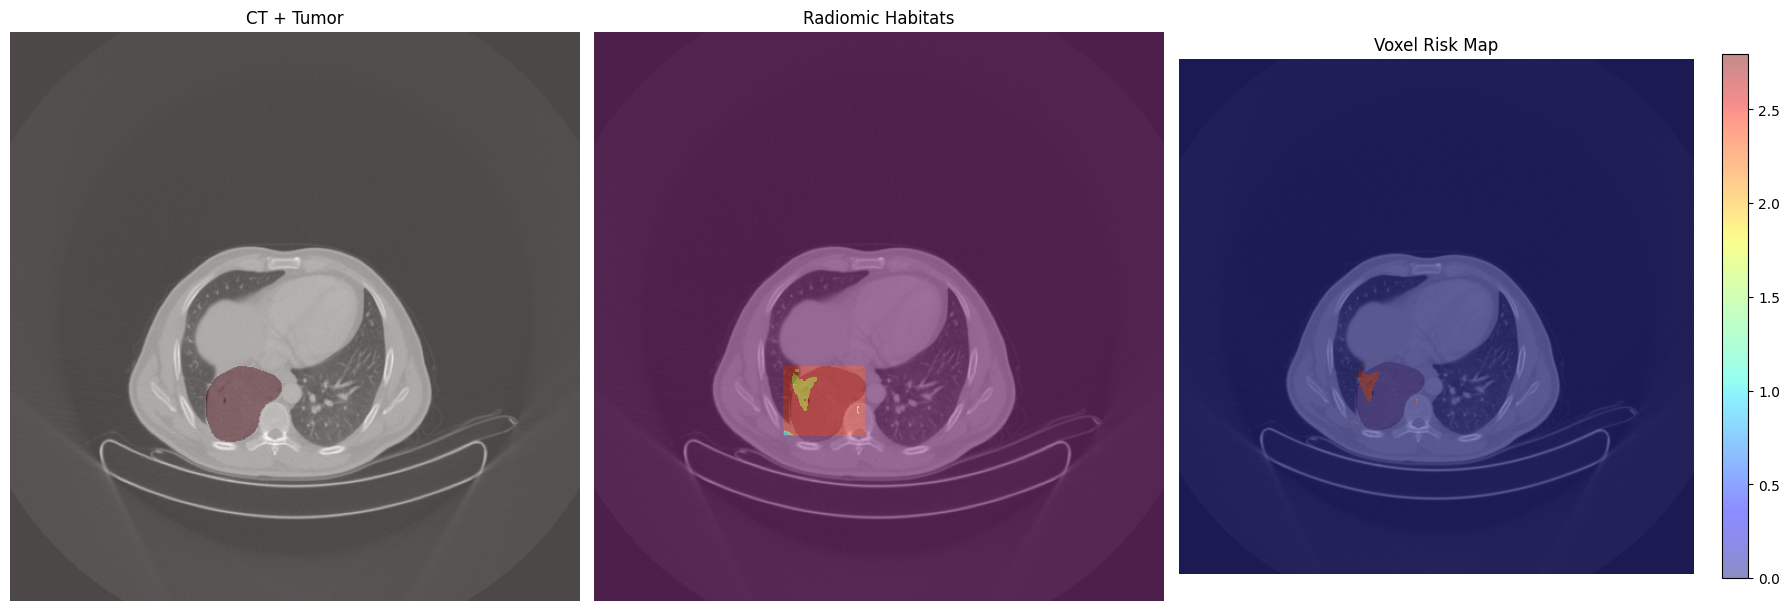

In [ ]:
# old

In [95]:
visualize_habitats_interactive(
    patient_id="110348284",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

CT shape: (426, 512, 512)
Mask shape: (426, 512, 512)
Spacing: (1.171875, 1.171875, 2.000000238418579)
Radiomics map shape: (2, 73, 63, 73)


interactive(children=(IntSlider(value=276, description='Slice', max=310, min=242), Output()), _dom_classes=('w…

In [94]:
visualize_habitats_interactive(
    patient_id="136886792",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

CT shape: (94, 512, 512)
Mask shape: (94, 512, 512)
Spacing: (0.685546875, 0.685546875, 5.0)
Radiomics map shape: (2, 62, 45, 59)


interactive(children=(IntSlider(value=60, description='Slice', max=72, min=49), Output()), _dom_classes=('widg…

### gb dont use



In [ ]:
############################################################
# FINAL SCRIPT — COMPLETE (FEATURE SELECTION + CM + CINDEX)
############################################################

import os, time
import numpy as np
import pandas as pd
import SimpleITK as sitk
import matplotlib.pyplot as plt
import seaborn as sns

from minisom import MiniSom
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, confusion_matrix, adjusted_rand_score
from lifelines import CoxPHFitter
from lifelines.utils import concordance_index
from scipy.optimize import linear_sum_assignment
from scipy.stats import entropy
from tqdm import tqdm

############################################################
# REPRODUCIBILITY
############################################################

SEED = 88
np.random.seed(SEED)

############################################################
# CONFIG
############################################################

TMH_TRAIN = "/TMH/train/"
TMH_TEST  = "/TMH/test/"

LUNG_TRAIN = "/LUNG1/train/"
LUNG_TEST  = "/LUNG1/test/"

TMH_SURV = "/tmh_survival.csv"
LUNG_SURV = "/lung_survival.csv"

SOM_X, SOM_Y = 2,2
N_CLUSTERS = 4

FEATURE_THRESHOLD = 0.7
MAX_VOXELS = 200000
SILHOUETTE_SAMPLE = 50000

############################################################
# LOAD MAPS
############################################################

def load_maps(pdir):
    maps, names = [], []
    for f in sorted(os.listdir(pdir)):
        if f.endswith(".nrrd"):
            names.append(f.split("gldm_")[-1].replace(".nrrd",""))
            maps.append(sitk.GetArrayFromImage(
                sitk.ReadImage(os.path.join(pdir,f))
            ))
    return np.stack(maps), names

############################################################
# FAST  LABEL ASSIGN
############################################################

def fast_assign(vox, som):
    weights = som.get_weights().reshape(-1, vox.shape[1])
    dists = np.linalg.norm(vox[:, None, :] - weights[None,:,:], axis=2)
    return np.argmin(dists, axis=1)

############################################################
# FEATURE SELECTION (WITH SAMPLING)
############################################################

def select_features(dataset):

    print("\nSTEP 1 — Feature Selection")

    patients = sorted(os.listdir(dataset))
    maps, names = load_maps(os.path.join(dataset, patients[0]))

    scores = []

    for f in tqdm(range(len(names)), desc="Features"):

        np.random.seed(SEED + f)

        all_pixels = []

        for p in patients:
            m,_ = load_maps(os.path.join(dataset,p))
            all_pixels.append(m[f].reshape(-1,1))

        all_pixels = np.vstack(all_pixels)

        # sampling
        if all_pixels.shape[0] > MAX_VOXELS:
            idx = np.random.choice(all_pixels.shape[0], MAX_VOXELS, replace=False)
            all_pixels = all_pixels[idx]

        scaler = StandardScaler()
        all_pixels = scaler.fit_transform(all_pixels)

        som = MiniSom(SOM_X, SOM_Y, input_len=1,
                      sigma=0.8, learning_rate=0.3)

        som.random_weights_init(all_pixels)
        som.train_random(all_pixels,10000)

        labels = fast_assign(all_pixels, som)

        score = silhouette_score(
            all_pixels,
            labels,
            sample_size=min(SILHOUETTE_SAMPLE, len(all_pixels)),
            random_state=SEED
        )

        scores.append(score)

    selected = [n for s,n in zip(scores,names) if s >= FEATURE_THRESHOLD]

    print("\nSelected Features:")
    for n,s in zip(names,scores):
        if s >= FEATURE_THRESHOLD:
            print(n, "→", round(s,4))

    return selected

############################################################
# COLLECT VOXELS
############################################################

def collect_voxels(dataset, features):

    vox = []

    for p in os.listdir(dataset):
        m,n = load_maps(os.path.join(dataset,p))
        idx = [n.index(f) for f in features]
        vox.append(m[idx].reshape(len(idx),-1).T)

    return np.vstack(vox)

############################################################
# TRAIN SOM
############################################################

def train_som(vox):

    scaler = StandardScaler()
    vox = scaler.fit_transform(vox)

    if vox.shape[0] > 100000:
        idx = np.random.choice(vox.shape[0], 100000, replace=False)
        vox = vox[idx]

    som = MiniSom(SOM_X, SOM_Y, vox.shape[1],
                  sigma=0.8, learning_rate=0.3)

    som.train_random(vox,10000)

    return som, scaler

############################################################
# PREDICT DATASET
############################################################

def predict_dataset(dataset, features, som, scaler):

    labels_all = []

    for p in os.listdir(dataset):

        m,n = load_maps(os.path.join(dataset,p))
        idx = [n.index(f) for f in features]

        vox = m[idx].reshape(len(idx),-1).T
        vox = scaler.transform(vox)

        labels = fast_assign(vox, som)
        labels_all.append(labels)

    return np.concatenate(labels_all)

############################################################
# CONFUSION MATRIX
############################################################

def compare_models(labels1, labels2, title):

    cm = confusion_matrix(labels1, labels2)

    r,c = linear_sum_assignment(-cm)
    mapping = {col:row for row,col in zip(r,c)}

    aligned = np.array([mapping[l] for l in labels2])

    cm_aligned = confusion_matrix(labels1, aligned)
    cm_norm = cm_aligned / cm_aligned.sum(axis=1, keepdims=True)

    acc = np.mean(labels1 == aligned)
    ari = adjusted_rand_score(labels1, labels2)

    print("\n",title)
    print("Accuracy:",acc)
    print("ARI:",ari)

    plt.figure(figsize=(12,5))

    plt.subplot(1,2,1)
    sns.heatmap(cm_aligned,annot=True,fmt="d",cmap="Blues")
    plt.title("Confusion Matrix")

    plt.subplot(1,2,2)
    sns.heatmap(cm_norm,annot=True,fmt=".2f",cmap="Blues")
    plt.title("Normalized")

    plt.show()

############################################################
# PATIENT FEATURES
############################################################

def patient_features(dataset, features, som, scaler):

    rows, ids = [], []

    for p in os.listdir(dataset):

        m,n = load_maps(os.path.join(dataset,p))
        idx = [n.index(f) for f in features]

        vox = m[idx].reshape(len(idx),-1).T
        vox = scaler.transform(vox)

        labels = fast_assign(vox, som)

        props = np.bincount(labels, minlength=N_CLUSTERS)/len(labels)
        ent = entropy(props)

        rows.append(list(props)+[ent])
        ids.append(p)

    df = pd.DataFrame(rows,
        columns=[f"H{i}" for i in range(N_CLUSTERS)] + ["Entropy"]
    )

    df["Patient"] = ids
    return df

############################################################
# ================= MAIN =================
############################################################

start = time.time()

############################################################
# STEP 1 — FEATURE SELECTION
############################################################

features = select_features(TMH_TRAIN)

############################################################
# STEP 2 — TRAIN MODELS
############################################################

tmh_vox = collect_voxels(TMH_TRAIN, features)
som_tmh, scaler_tmh = train_som(tmh_vox)

lung_vox = collect_voxels(LUNG_TRAIN, features)
som_lung, scaler_lung = train_som(lung_vox)

############################################################
# STEP 3 — CONFUSION MATRICES
############################################################

tmh_ref = predict_dataset(TMH_TEST, features, som_tmh, scaler_tmh)
tmh_other = predict_dataset(TMH_TEST, features, som_lung, scaler_lung)

compare_models(tmh_ref, tmh_other, "TMH TEST")

lung_ref = predict_dataset(LUNG_TEST, features, som_tmh, scaler_tmh)
lung_other = predict_dataset(LUNG_TEST, features, som_lung, scaler_lung)

compare_models(lung_ref, lung_other, "LUNG1 TEST")

############################################################
# STEP 4 — SURVIVAL (TMH MODEL)
############################################################

tmh_train_feat = patient_features(TMH_TRAIN, features, som_tmh, scaler_tmh)
tmh_test_feat  = patient_features(TMH_TEST,  features, som_tmh, scaler_tmh)
lung_test_feat = patient_features(LUNG_TEST, features, som_tmh, scaler_tmh)

tmh_surv = pd.read_csv(TMH_SURV)
lung_surv = pd.read_csv(LUNG_SURV)

tmh_train = pd.merge(tmh_train_feat, tmh_surv, on="Patient")
tmh_test  = pd.merge(tmh_test_feat, tmh_surv, on="Patient")
lung_test = pd.merge(lung_test_feat, lung_surv, on="Patient")

cph = CoxPHFitter(penalizer=0.2)
cph.fit(tmh_train.drop(columns=["Patient"]),
        duration_col="time", event_col="event")

############################################################
# C-INDEX
############################################################

print("\nC-INDEX")

print("TMH Train:",
      concordance_index(tmh_train["time"],
      -cph.predict_partial_hazard(tmh_train),
      tmh_train["event"]))

print("TMH Test:",
      concordance_index(tmh_test["time"],
      -cph.predict_partial_hazard(tmh_test),
      tmh_test["event"]))

print("LUNG1 External:",
      concordance_index(lung_test["time"],
      -cph.predict_partial_hazard(lung_test),
      lung_test["event"]))

############################################################

print("\nTOTAL TIME:", round((time.time()-start)/60,2), "minutes")


PIPELINE START
[TIME] Previous step: 0.0 sec

STEP 1 — SOM Feature Selection


Features: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 14/14 [00:00<00:00, 44217.06it/s]



Selected features:
LargeDependenceLowGrayLevelEmphasis  --->  Silhouette: 0.8932
LowGrayLevelEmphasis  --->  Silhouette: 0.8137
[INFO] Total selected: 2
[TIME] Previous step: 62.69 sec

STEP 2 — Collect Voxels


TMH Voxels: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:04<00:00, 24.09it/s]


[TIME] Previous step: 4.91 sec

STEP 3 — Train SOM
[TIME] Previous step: 0.74 sec

STEP 4 — Cross Dataset Reproducibility


LUNG1 Voxels: 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 120/120 [00:03<00:00, 32.58it/s]


[TIME] Previous step: 6.24 sec

STEP 4 — Cluster Reproducibility
Accuracy: 0.9854691144749481
ARI: 0.9737409573655937


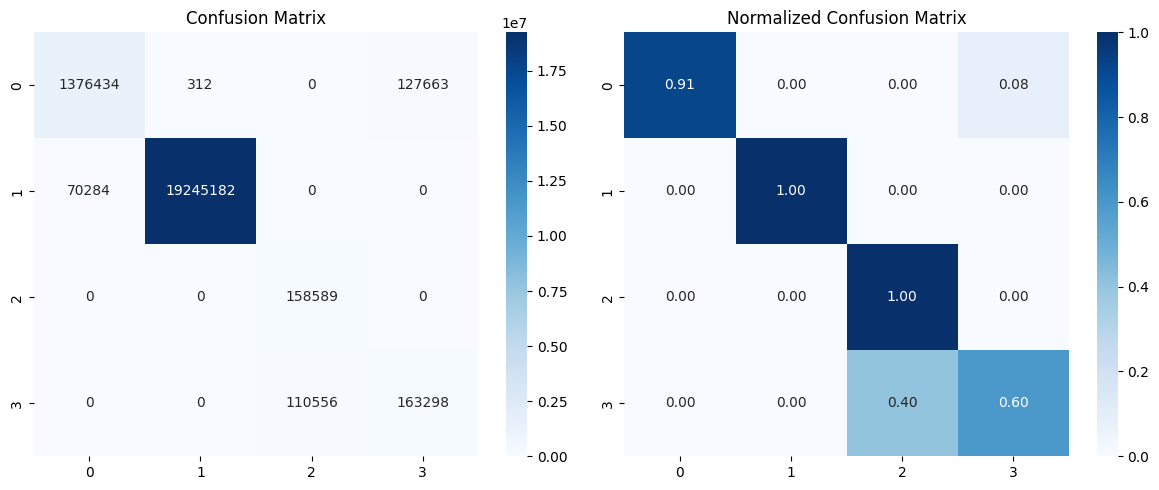

[TIME] Previous step: 3.45 sec

STEP 5 — Habitat Feature Extraction


Patients: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 117/117 [00:00<00:00, 1711.31it/s]


[TIME] Previous step: 0.95 sec

STEP 6 — Survival Analysis
               coef  exp(coef)  se(coef)  coef lower 95%  coef upper 95%  \
covariate                                                                  
H0         0.021873   1.022114  1.335448       -2.595558        2.639304   
H1        -0.111616   0.894388  1.223841       -2.510300        2.287068   
H2         2.589754  13.326489  4.140753       -5.525973       10.705480   
H3        -0.197819   0.820518  5.375172      -10.732963       10.337324   
Entropy   -0.076020   0.926798  0.629618       -1.310050        1.158009   

           exp(coef) lower 95%  exp(coef) upper 95%  cmp to         z  \
covariate                                                               
H0                    0.074604            14.003448     0.0  0.016379   
H1                    0.081244             9.846031     0.0 -0.091201   
H2                    0.003982         44599.604155     0.0  0.625431   
H3                    0.000022         3086

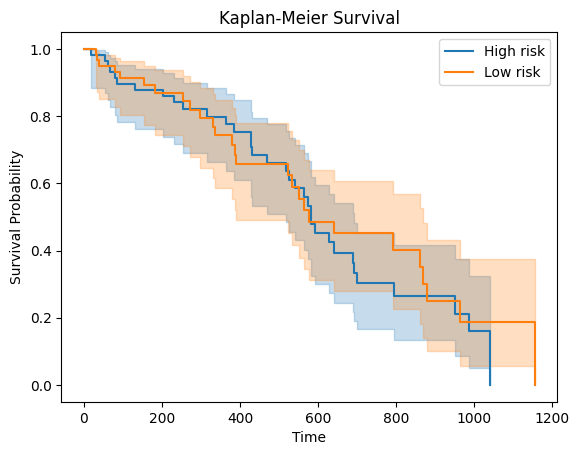

[TIME] Previous step: 0.06 sec

PIPELINE COMPLETED

TOTAL TIME: 1.32 minutes


In [ ]:
#

In [24]:
############################################################
# SCRIPT B — VISUALIZATION
############################################################

import os, numpy as np, SimpleITK as sitk
import matplotlib.pyplot as plt
from scipy.ndimage import zoom

def visualize(patient_id,
              radiomics_dir,
              ct_mask_dir,
              selected_features,
              som,
              scaler,
              habitat_weights):

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir,patient_id,"CT.nii.gz"))
    )

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir,patient_id,"mask.nii.gz"))
    )

    maps,names = load_maps(os.path.join(radiomics_dir,patient_id))

    idx=[names.index(f) for f in selected_features]
    maps=maps[idx]

    scale = (
        ct.shape[0]/maps.shape[1],
        ct.shape[1]/maps.shape[2],
        ct.shape[2]/maps.shape[3]
    )

    maps_up = np.array([zoom(m,scale,order=1) for m in maps])

    vox = maps_up.reshape(len(idx),-1).T
    labels = assign(vox,som,scaler)

    habitat = labels.reshape(ct.shape)

    risk = np.zeros_like(habitat,dtype=float)

    for k,v in habitat_weights.items():
        c=int(k[1])
        risk[habitat==c]=v

    slices=np.where(mask.sum(axis=(1,2))>0)[0]
    s = slices[len(slices)//2] if len(slices)>0 else ct.shape[0]//2

    plt.figure(figsize=(15,5))

    plt.subplot(1,3,1)
    plt.imshow(ct[s],cmap="gray")
    plt.imshow(mask[s],alpha=0.3)
    plt.title("CT + Tumor")

    plt.subplot(1,3,2)
    plt.imshow(ct[s],cmap="gray")
    plt.imshow(habitat[s],alpha=0.5,cmap="tab10")
    plt.title("Habitat")

    plt.subplot(1,3,3)
    plt.imshow(ct[s],cmap="gray")
    plt.imshow(risk[s],alpha=0.5,cmap="jet")
    plt.title("Risk")

    plt.show()

In [28]:
visualize(
    patient_id="120433028",
    radiomics_dir=TMH_DIR,
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

KeyboardInterrupt: 

In [27]:
habitat_weights

{'H0': 131.67779943156037, 'H1': -1395.1057614907127, 'H2': 0.8365596847248342}

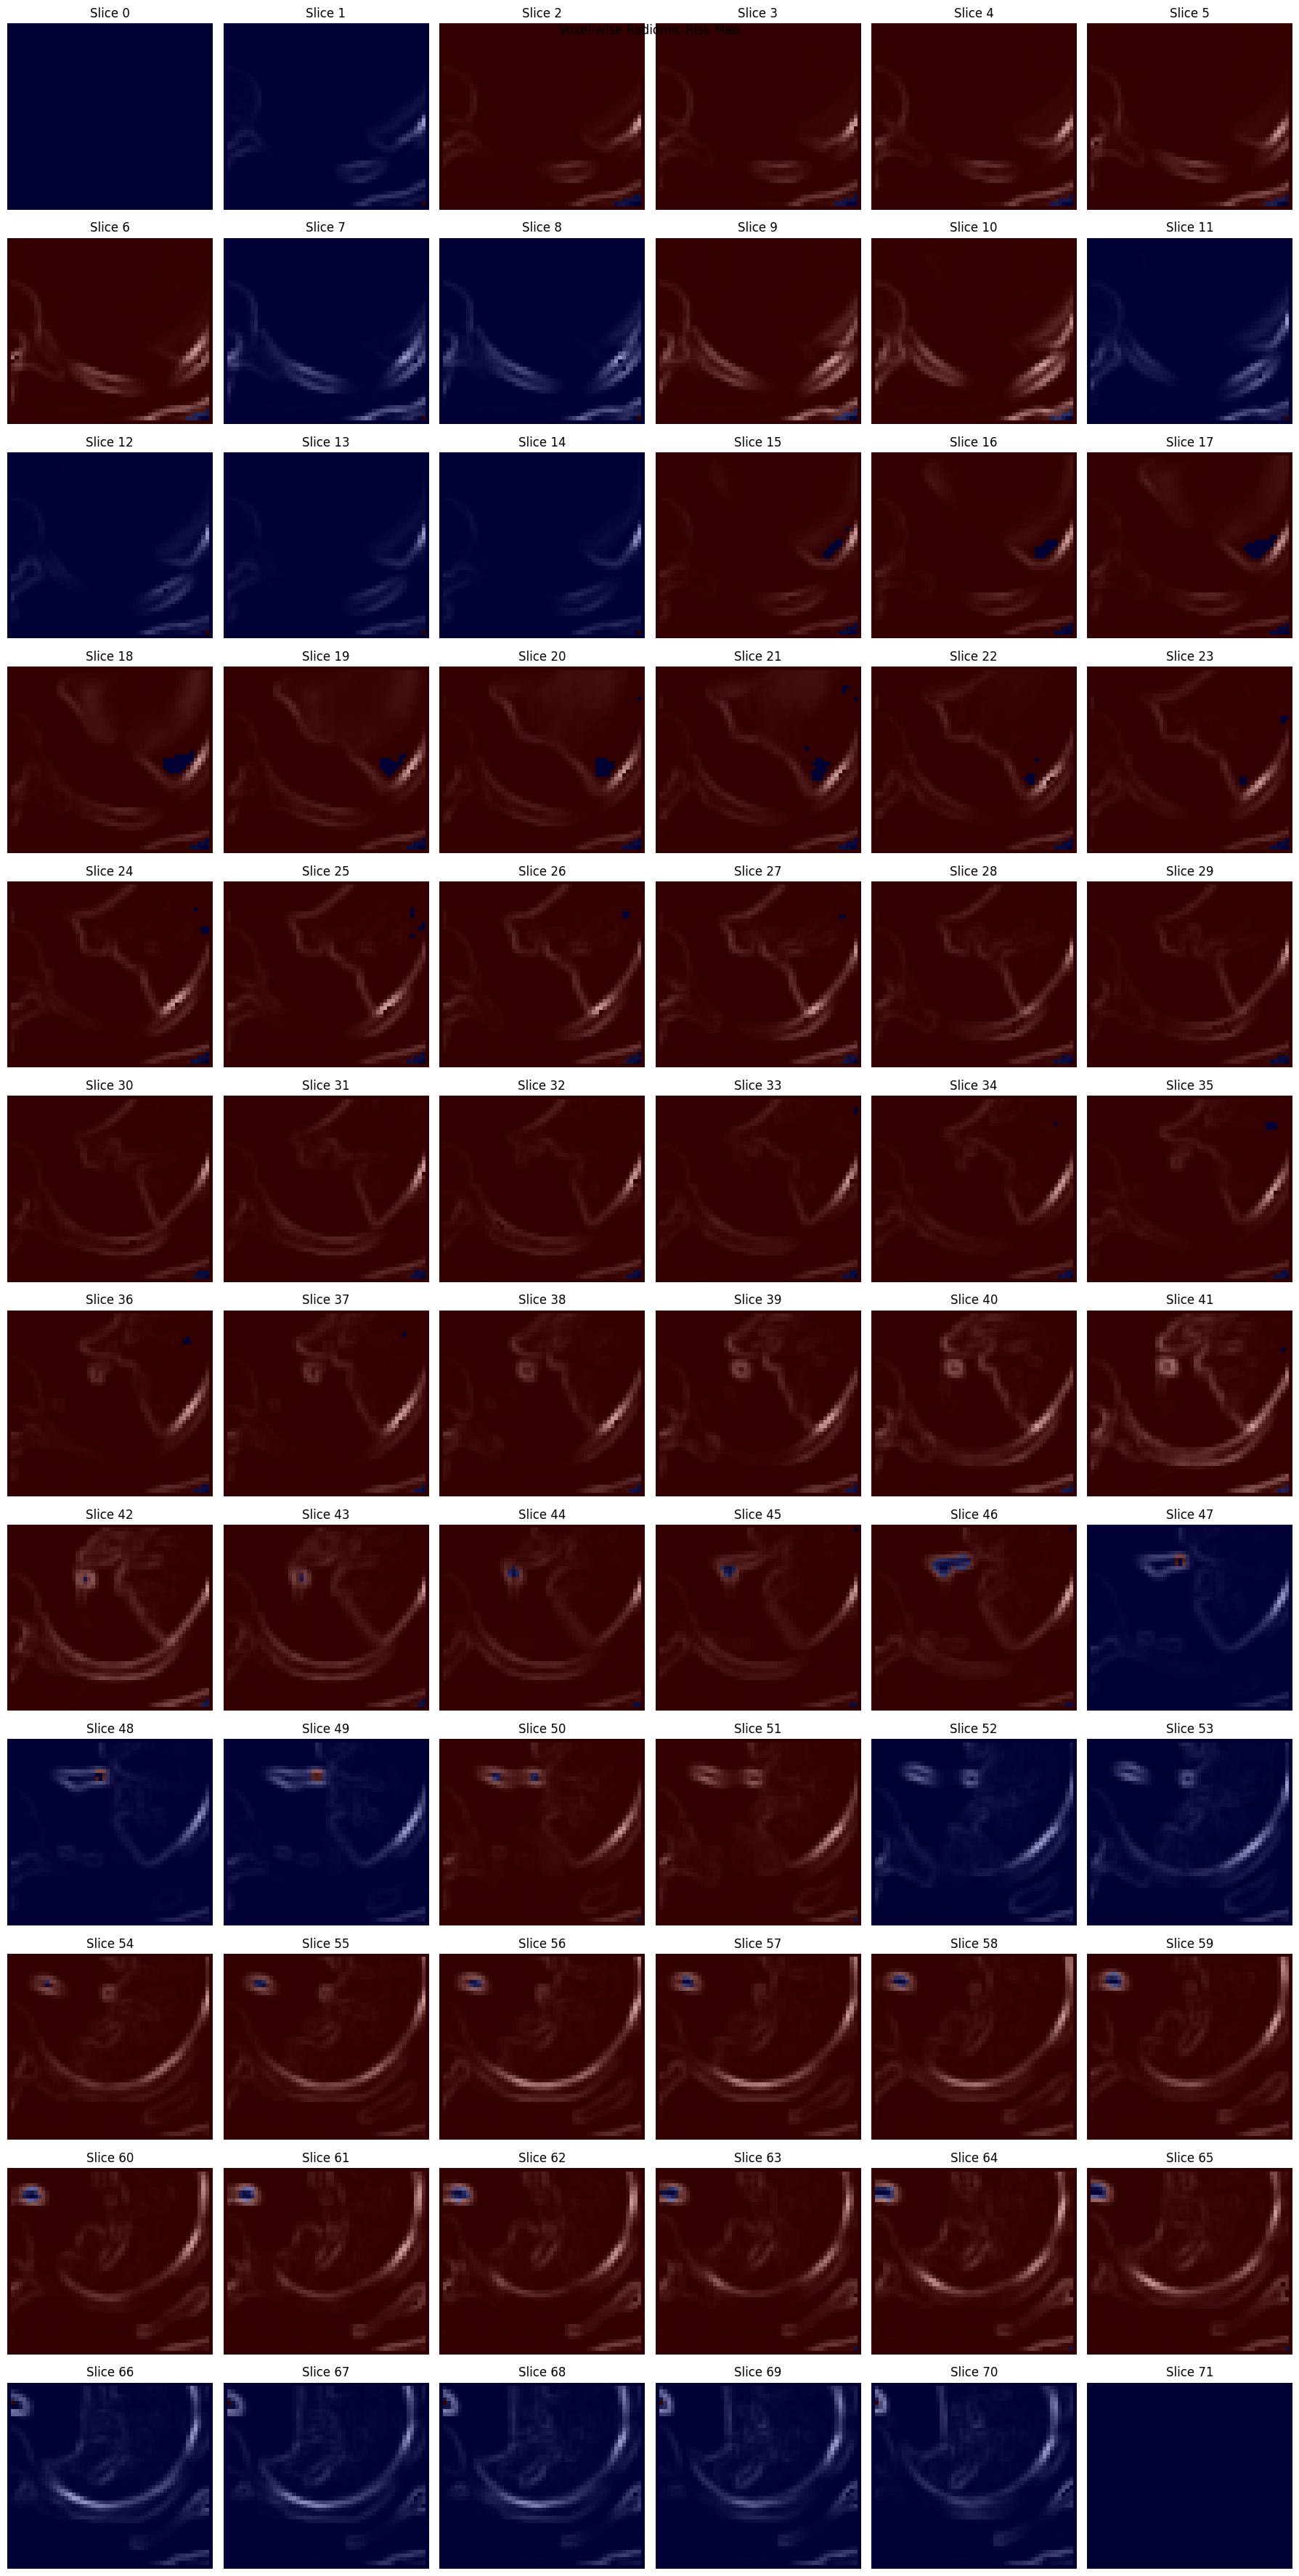

In [7]:
############################################################
# Example patient visualization
############################################################

example_patient = os.path.join(TMH_DIR, os.listdir(TMH_DIR)[0])

risk_map = voxel_risk_map(
    example_patient,
    selected_features,
    som_tmh,
    scaler_tmh,
    habitat_weights
)

# load CT for visualization
ct_map,_ = load_patient_maps(example_patient)
ct_volume = ct_map[5]

plot_risk_overlay(ct_volume,risk_map)

In [71]:
len(ct_map)

14

In [67]:
example_patient

'/home/user/Desktop/20_mm_final/TMH/gldm/10/139712992'

In [ ]:
# note we have to add the h3 back in cox after testing

In [8]:
import SimpleITK as sitk
import numpy as np
import matplotlib.pyplot as plt
import os

def visualize_patient_habitats(patient_id,
                               radiomics_dir,
                               ct_mask_dir,
                               selected_features,
                               som,
                               scaler,
                               habitat_weights):

    ########################################
    # Load CT and mask
    ########################################

    ct_path = os.path.join(ct_mask_dir, patient_id, "CT.nii.gz")
    mask_path = os.path.join(ct_mask_dir, patient_id, "mask.nii.gz")

    ct = sitk.GetArrayFromImage(sitk.ReadImage(ct_path))
    mask = sitk.GetArrayFromImage(sitk.ReadImage(mask_path))

    ########################################
    # Load radiomics feature maps
    ########################################

    patient_rad_dir = os.path.join(radiomics_dir, patient_id)

    maps = []
    names = []

    for f in sorted(os.listdir(patient_rad_dir)):

        if f.endswith(".nrrd"):

            name = f.split("gldm_")[-1].replace(".nrrd","")

            if name in selected_features:

                img = sitk.ReadImage(os.path.join(patient_rad_dir,f))
                arr = sitk.GetArrayFromImage(img)

                maps.append(arr)
                names.append(name)

    maps = np.stack(maps)

    ########################################
    # Compute habitats
    ########################################

    vox = maps.reshape(len(selected_features), -1).T

    labels = []

    vox_scaled = scaler.transform(vox)

    for v in vox_scaled:

        w = som.winner(v)
        labels.append(w[0]*2 + w[1])

    labels = np.array(labels)

    z,h,w = maps.shape[1:]

    habitat_map = labels.reshape(z,h,w)

    ########################################
    # Risk map
    ########################################

    risk_map = np.zeros_like(habitat_map,dtype=float)

    for c in range(4):

        weight = habitat_weights.get(f"H{c}",0)

        risk_map[habitat_map==c] = weight

    ########################################
    # Choose central tumor slice
    ########################################

    tumor_slices = np.where(mask.sum(axis=(1,2))>0)[0]

    slice_id = tumor_slices[len(tumor_slices)//2]

    ct_slice = ct[slice_id]
    mask_slice = mask[slice_id]
    habitat_slice = habitat_map[slice_id]
    risk_slice = risk_map[slice_id]

    ########################################
    # Plot
    ########################################

    fig,axes = plt.subplots(1,3,figsize=(15,5))

    # Panel A
    axes[0].imshow(ct_slice,cmap="gray")
    axes[0].contour(mask_slice,colors="red",linewidths=1)
    axes[0].set_title("CT + Tumor Mask")
    axes[0].axis("off")

    # Panel B
    axes[1].imshow(ct_slice,cmap="gray")
    axes[1].imshow(habitat_slice,cmap="tab10",alpha=0.45)
    axes[1].contour(mask_slice,colors="white",linewidths=1)
    axes[1].set_title("Radiomic Habitats")
    axes[1].axis("off")

    # Panel C
    axes[2].imshow(ct_slice,cmap="gray")
    axes[2].imshow(risk_slice,cmap="jet",alpha=0.45)
    axes[2].contour(mask_slice,colors="white",linewidths=1)
    axes[2].set_title("Voxel Risk Map")
    axes[2].axis("off")

    plt.tight_layout()
    plt.show()

In [9]:
visualize_patient_habitats(
    patient_id="120433028",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=selected_features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

IndexError: index 238 is out of bounds for axis 0 with size 77

In [10]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap


def visualize_patient_habitats(
        patient_id,
        radiomics_dir,
        ct_mask_dir,
        selected_features,
        som,
        scaler,
        habitat_weights):

    ########################################
    # Load CT and mask
    ########################################

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir,patient_id,"CT.nii.gz"))
    )

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir,patient_id,"mask.nii.gz"))
    )

    print("CT shape:",ct.shape)
    print("Mask shape:",mask.shape)

    ########################################
    # Load radiomics maps
    ########################################

    rad_dir = os.path.join(radiomics_dir,patient_id)

    feature_maps=[]

    for f in sorted(os.listdir(rad_dir)):

        if f.endswith(".nrrd"):

            name = f.split("gldm_")[-1].replace(".nrrd","")

            if name in selected_features:

                arr = sitk.GetArrayFromImage(
                    sitk.ReadImage(os.path.join(rad_dir,f))
                )

                feature_maps.append(arr)

    feature_maps=np.stack(feature_maps)

    print("Radiomics map shape:",feature_maps.shape)

    ########################################
    # SOM clustering
    ########################################

    roi_shape = feature_maps.shape[1:]

    vox = feature_maps.reshape(len(selected_features),-1).T
    vox = scaler.transform(vox)

    SOM_Y = som._weights.shape[1]

    labels=[]

    for v in vox:

        w=som.winner(v)
        labels.append(w[0]*SOM_Y+w[1])

    labels=np.array(labels)

    habitat_roi = labels.reshape(roi_shape)

    ########################################
    # Risk map
    ########################################

    risk_roi=np.zeros(roi_shape)

    for k,v in habitat_weights.items():

        c=int(k.replace("H",""))

        risk_roi[habitat_roi==c]=v

    ########################################
    # Compute tumor center
    ########################################

    coords=np.where(mask>0)

    cz=int(np.mean(coords[0]))
    cy=int(np.mean(coords[1]))
    cx=int(np.mean(coords[2]))

    ########################################
    # Compute ROI start indices
    ########################################

    z0 = cz - roi_shape[0]//2
    y0 = cy - roi_shape[1]//2
    x0 = cx - roi_shape[2]//2

    z0=max(0,z0)
    y0=max(0,y0)
    x0=max(0,x0)

    ########################################
    # Insert ROI into CT space
    ########################################

    habitat_full=np.zeros(ct.shape)
    risk_full=np.zeros(ct.shape)

    z1=min(z0+roi_shape[0],ct.shape[0])
    y1=min(y0+roi_shape[1],ct.shape[1])
    x1=min(x0+roi_shape[2],ct.shape[2])

    habitat_full[z0:z1,y0:y1,x0:x1]=habitat_roi[:z1-z0,:y1-y0,:x1-x0]
    risk_full[z0:z1,y0:y1,x0:x1]=risk_roi[:z1-z0,:y1-y0,:x1-x0]

    ########################################
    # Choose tumor slice
    ########################################

    # tumor_slices=np.where(mask.sum(axis=(1,2))>0)[0]

    # slice_id=tumor_slices[len(tumor_slices)//2]



    ########################################
    # Choose slice with maximum tumor area
    ########################################
    
    tumor_slices = np.where(mask.sum(axis=(1,2)) > 0)[0]
    
    # compute tumor area per slice
    tumor_areas = mask.sum(axis=(1,2))
    
    # choose slice with largest tumor area
    slice_id = tumor_slices[np.argmax(tumor_areas[tumor_slices])]

    print(slice_id,'slice_id')

    ct_slice=ct[slice_id]
    mask_slice=mask[slice_id]
    habitat_slice=habitat_full[slice_id]
    risk_slice=risk_full[slice_id]

    ########################################
    # Plot
    ########################################

    habitat_cmap=ListedColormap(["purple","cyan","yellow","red"])

    fig,axes=plt.subplots(1,3,figsize=(18,6))

    axes[0].imshow(ct_slice,cmap="gray")
    axes[0].imshow(mask_slice,cmap="Reds",alpha=0.3)
    axes[0].set_title("CT + Tumor")
    axes[0].axis("off")

    axes[1].imshow(ct_slice,cmap="gray")
    axes[1].imshow(mask_slice,cmap="Reds",alpha=0.2)
    axes[1].imshow(habitat_slice,cmap=habitat_cmap,
                   alpha=0.35,interpolation="nearest")
    axes[1].set_title("Radiomic Habitats")
    axes[1].axis("off")

    axes[2].imshow(ct_slice,cmap="gray")
    axes[2].imshow(mask_slice,cmap="Reds",alpha=0.2)

    im=axes[2].imshow(risk_slice,cmap="jet",
                      alpha=0.45,interpolation="nearest")

    axes[2].set_title("Voxel Risk Map")
    axes[2].axis("off")

    plt.colorbar(im,ax=axes[2],fraction=0.046)

    plt.tight_layout()
    plt.show()

CT shape: (383, 512, 512)
Mask shape: (383, 512, 512)
Radiomics map shape: (4, 69, 61, 57)
235 slice_id


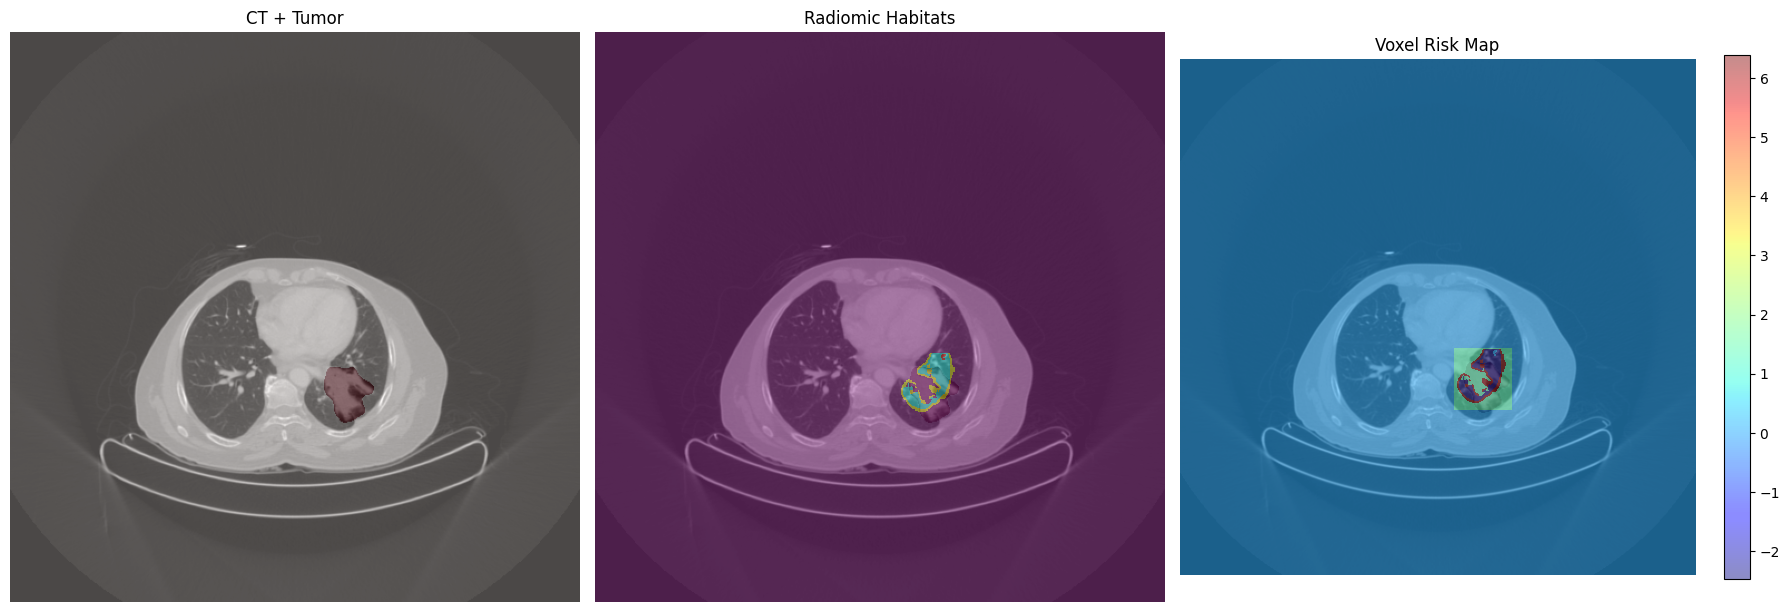

In [63]:
visualize_patient_habitats(
    patient_id="105131012",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=selected_features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

CT shape: (383, 512, 512)
Mask shape: (383, 512, 512)
Radiomics map shape: (2, 69, 61, 57)
235 slice_id


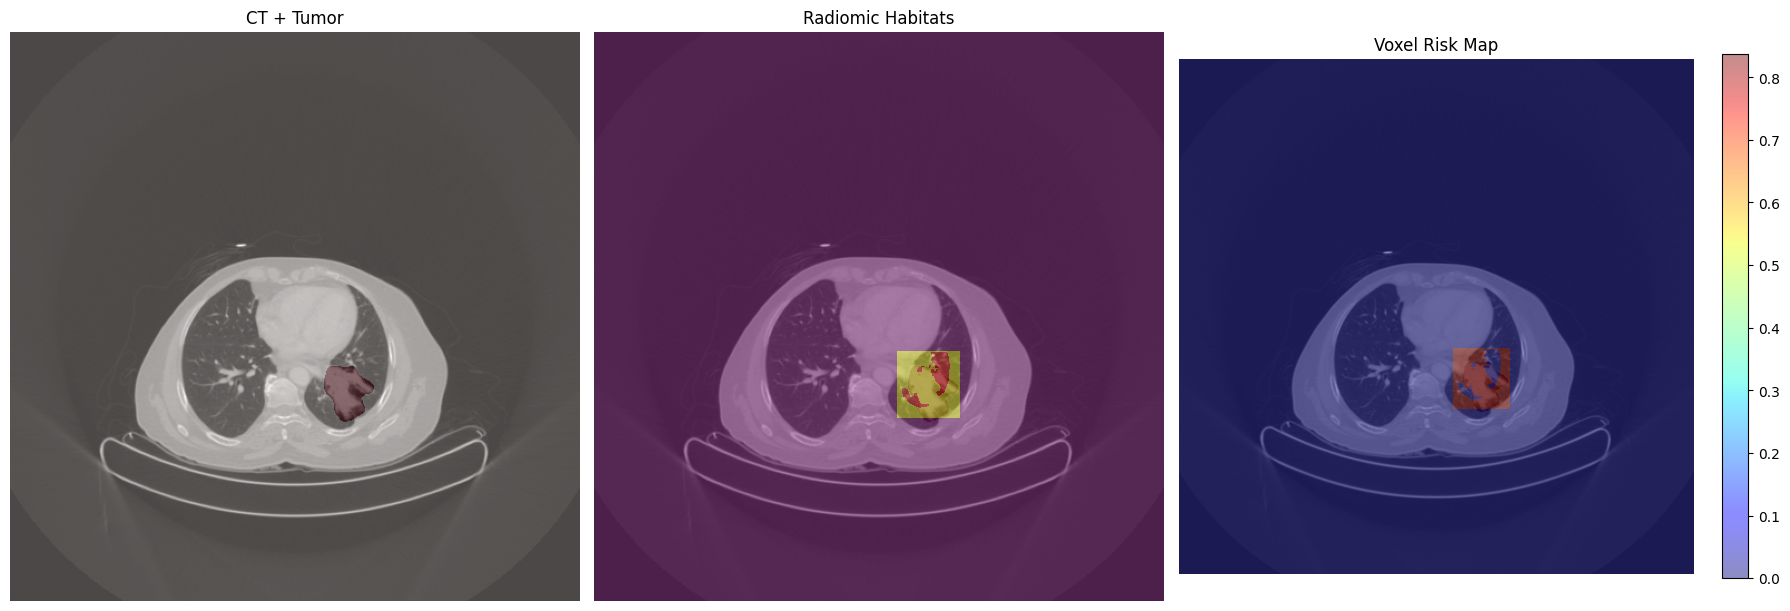

In [14]:
visualize_patient_habitats(
    patient_id="105131012",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=selected_features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

CT shape: (383, 512, 512)
Mask shape: (383, 512, 512)
Radiomics map shape: (2, 69, 61, 57)
235 slice_id


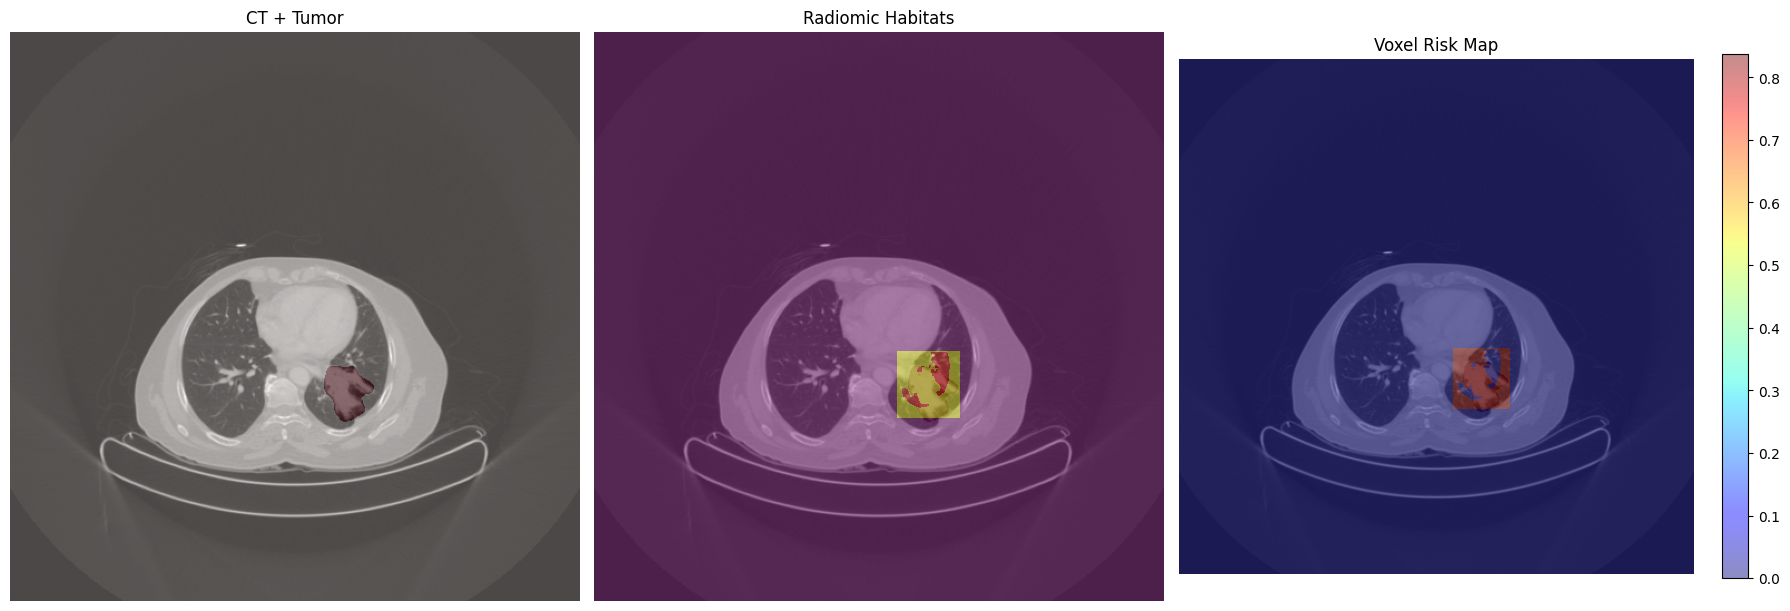

In [15]:
visualize_patient_habitats(
    patient_id="105131012",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=selected_features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

In [55]:
habitat_weights

{'H0': 1.3285038905456206, 'H1': -2.4745633499582085, 'H2': 6.389816689725936}

In [ ]:
# gb final scrol patient view

In [44]:
def scroll_patient_habitats_new(
        patient_id,
        radiomics_dir,
        ct_mask_dir,
        selected_features,
        som,
        scaler,
        habitat_weights):

    import os
    import numpy as np
    import SimpleITK as sitk
    import matplotlib.pyplot as plt
    from matplotlib.colors import ListedColormap
    import ipywidgets as widgets

    ########################################
    # Load CT and mask
    ########################################

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir, patient_id, "CT.nii.gz"))
    )

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir, patient_id, "mask.nii.gz"))
    )

    print("CT shape:", ct.shape)
    print("Mask shape:", mask.shape)

    if np.sum(mask) == 0:
        print("❌ No tumor mask found")
        return

    ########################################
    # Load radiomics maps
    ########################################

    rad_dir = os.path.join(radiomics_dir, patient_id)

    feature_maps = []

    for f in sorted(os.listdir(rad_dir)):
        if f.endswith(".nrrd"):

            name = f.split("gldm_")[-1].replace(".nrrd", "")

            if name in selected_features:

                arr = sitk.GetArrayFromImage(
                    sitk.ReadImage(os.path.join(rad_dir, f))
                )

                feature_maps.append(arr)

    feature_maps = np.stack(feature_maps)

    print("Radiomics map shape:", feature_maps.shape)

    ########################################
    # SOM clustering (FAST + VECTOR)
    ########################################

    roi_shape = feature_maps.shape[1:]

    vox = feature_maps.reshape(len(selected_features), -1).T
    vox = scaler.transform(vox)

    weights = som.get_weights().reshape(-1, vox.shape[1])

    dists = np.linalg.norm(
        vox[:, None, :] - weights[None, :, :],
        axis=2
    )

    labels = np.argmin(dists, axis=1)

    habitat_roi = labels.reshape(roi_shape)

    ########################################
    # Risk map (FULL SAFE)
    ########################################

    risk_roi = np.zeros_like(habitat_roi, dtype=float)

    for k, v in habitat_weights.items():
        c = int(k.replace("H", ""))
        risk_roi[habitat_roi == c] = v

    ########################################
    # Find tumor bounding box (BETTER THAN CENTER)
    ########################################

    coords = np.where(mask > 0)

    zmin, zmax = coords[0].min(), coords[0].max()
    ymin, ymax = coords[1].min(), coords[1].max()
    xmin, xmax = coords[2].min(), coords[2].max()

    ########################################
    # Insert ROI into CT space (CORRECT ALIGNMENT)
    ########################################

    habitat_full = np.zeros_like(ct)
    risk_full = np.zeros_like(ct)

    dz = min(roi_shape[0], zmax - zmin + 1)
    dy = min(roi_shape[1], ymax - ymin + 1)
    dx = min(roi_shape[2], xmax - xmin + 1)

    habitat_full[zmin:zmin+dz, ymin:ymin+dy, xmin:xmin+dx] = \
        habitat_roi[:dz, :dy, :dx]

    risk_full[zmin:zmin+dz, ymin:ymin+dy, xmin:xmin+dx] = \
        risk_roi[:dz, :dy, :dx]

    ########################################
    # MASK RESTRICTION (VERY IMPORTANT)
    ########################################

    habitat_full[mask == 0] = np.nan
    risk_full[mask == 0] = np.nan

    ########################################
    # Dynamic colormap
    ########################################

    n_clusters = len(np.unique(labels))
    colors = plt.cm.tab10(np.linspace(0, 1, n_clusters))
    habitat_cmap = ListedColormap(colors)

    ########################################
    # Interactive viewer
    ########################################

    def view_slice(slice_id):

        fig, axes = plt.subplots(1, 3, figsize=(18, 6))

        # CT + tumor
        axes[0].imshow(ct[slice_id], cmap="gray")
        axes[0].imshow(mask[slice_id], cmap="Reds", alpha=0.3)
        axes[0].set_title(f"CT + Tumor (slice {slice_id})")
        axes[0].axis("off")

        # habitats
        axes[1].imshow(ct[slice_id], cmap="gray")
        axes[1].imshow(mask[slice_id], cmap="Reds", alpha=0.2)
        axes[1].imshow(
            habitat_full[slice_id],
            cmap=habitat_cmap,
            alpha=0.5,
            interpolation="nearest"
        )
        axes[1].set_title("Radiomic Habitats")
        axes[1].axis("off")

        # risk
        axes[2].imshow(ct[slice_id], cmap="gray")
        axes[2].imshow(mask[slice_id], cmap="Reds", alpha=0.2)

        im = axes[2].imshow(
            risk_full[slice_id],
            cmap="jet",
            alpha=0.5,
            interpolation="nearest"
        )

        axes[2].set_title("Voxel Risk Map")
        axes[2].axis("off")

        plt.colorbar(im, ax=axes[2], fraction=0.046)

        plt.tight_layout()
        plt.show()

    slider = widgets.IntSlider(
        min=zmin,
        max=zmax,
        step=1,
        value=(zmin + zmax) // 2,
        description="Slice"
    )

    widgets.interact(view_slice, slice_id=slider)

In [40]:
import os
import numpy as np
import SimpleITK as sitk
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import ipywidgets as widgets
from IPython.display import display


def scroll_patient_habitats(
        patient_id,
        radiomics_dir,
        ct_mask_dir,
        selected_features,
        som,
        scaler,
        habitat_weights):

    ########################################
    # Load CT and mask
    ########################################

    ct = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir,patient_id,"CT.nii.gz"))
    )

    mask = sitk.GetArrayFromImage(
        sitk.ReadImage(os.path.join(ct_mask_dir,patient_id,"mask.nii.gz"))
    )

    print("CT shape:",ct.shape)
    print("Mask shape:",mask.shape)

    ########################################
    # Load radiomics maps
    ########################################

    rad_dir = os.path.join(radiomics_dir,patient_id)

    feature_maps=[]

    for f in sorted(os.listdir(rad_dir)):

        if f.endswith(".nrrd"):

            name=f.split("gldm_")[-1].replace(".nrrd","")

            if name in selected_features:

                arr=sitk.GetArrayFromImage(
                    sitk.ReadImage(os.path.join(rad_dir,f))
                )

                feature_maps.append(arr)

    feature_maps=np.stack(feature_maps)

    print("Radiomics map shape:",feature_maps.shape)

    ########################################
    # SOM clustering
    ########################################

    roi_shape = feature_maps.shape[1:]

    vox = feature_maps.reshape(len(selected_features),-1).T
    vox = scaler.transform(vox)

    SOM_Y = som._weights.shape[1]

    labels=[]

    for v in vox:
        w=som.winner(v)
        labels.append(w[0]*SOM_Y+w[1])

    labels=np.array(labels)

    habitat_roi = labels.reshape(roi_shape)

    ########################################
    # Risk map
    ########################################

    risk_roi=np.zeros(roi_shape)

    for k,v in habitat_weights.items():

        c=int(k.replace("H",""))
        risk_roi[habitat_roi==c]=v

    ########################################
    # Compute tumor center
    ########################################

    coords=np.where(mask>0)

    cz=int(np.mean(coords[0]))
    cy=int(np.mean(coords[1]))
    cx=int(np.mean(coords[2]))

    ########################################
    # Insert ROI into CT space
    ########################################

    habitat_full=np.zeros(ct.shape)
    risk_full=np.zeros(ct.shape)

    z0 = max(0,cz-roi_shape[0]//2)
    y0 = max(0,cy-roi_shape[1]//2)
    x0 = max(0,cx-roi_shape[2]//2)

    z1=min(z0+roi_shape[0],ct.shape[0])
    y1=min(y0+roi_shape[1],ct.shape[1])
    x1=min(x0+roi_shape[2],ct.shape[2])

    habitat_full[z0:z1,y0:y1,x0:x1]=habitat_roi[:z1-z0,:y1-y0,:x1-x0]
    risk_full[z0:z1,y0:y1,x0:x1]=risk_roi[:z1-z0,:y1-y0,:x1-x0]

    ########################################
    # Colormap
    ########################################

    habitat_cmap=ListedColormap(["purple","cyan","yellow","red"])

    ########################################
    # Interactive viewer
    ########################################

    def view_slice(slice_id):

        fig,axes=plt.subplots(1,3,figsize=(18,6))

        # CT + tumor
        axes[0].imshow(ct[slice_id],cmap="gray")
        axes[0].imshow(mask[slice_id],cmap="Reds",alpha=0.3)
        axes[0].set_title(f"CT + Tumor (slice {slice_id})")
        axes[0].axis("off")

        # habitats
        axes[1].imshow(ct[slice_id],cmap="gray")
        axes[1].imshow(mask[slice_id],cmap="Reds",alpha=0.2)
        axes[1].imshow(habitat_full[slice_id],
                       cmap=habitat_cmap,
                       alpha=0.35,
                       interpolation="nearest")
        axes[1].set_title("Radiomic Habitats")
        axes[1].axis("off")

        # risk
        axes[2].imshow(ct[slice_id],cmap="gray")
        axes[2].imshow(mask[slice_id],cmap="Reds",alpha=0.2)

        im=axes[2].imshow(risk_full[slice_id],
                          cmap="jet",
                          alpha=0.45,
                          interpolation="nearest")

        axes[2].set_title("Voxel Risk Map")
        axes[2].axis("off")

        plt.colorbar(im,ax=axes[2],fraction=0.046)

        plt.tight_layout()
        plt.show()

    slider=widgets.IntSlider(
        min=0,
        max=ct.shape[0]-1,
        step=1,
        value=ct.shape[0]//2,
        description="Slice"
    )

    widgets.interact(view_slice,slice_id=slider)

In [42]:
selected_features

['LargeDependenceLowGrayLevelEmphasis', 'LowGrayLevelEmphasis']

In [55]:
scroll_patient_habitats(
    patient_id="105131012",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

CT shape: (383, 512, 512)
Mask shape: (383, 512, 512)
Radiomics map shape: (4, 69, 61, 57)


interactive(children=(IntSlider(value=234, description='Slice', max=257, min=211), Output()), _dom_classes=('w…

In [56]:
habitat_weights

{'H0': -0.8641058676504718,
 'H1': 0.11985975638858455,
 'H2': 2.7938544157327954}

In [ ]:
105131012
108689672
110348284
110670873
118623647
120433028
127940252
134593599
136210591
136886792

In [67]:
scroll_patient_habitats(
    patient_id="136210591",
    radiomics_dir="/home/user/Desktop/20_mm_final/TMH/gldm/10/",
    ct_mask_dir="/home/user/Desktop/gb_voxel_radiomics_input_files/gb_phd_dicoms/dcm_to_nii/",
    selected_features=features,
    som=som_tmh,
    scaler=scaler_tmh,
    habitat_weights=habitat_weights
)

CT shape: (110, 512, 512)
Mask shape: (110, 512, 512)
Radiomics map shape: (4, 74, 67, 40)


interactive(children=(IntSlider(value=84, description='Slice', max=94, min=74), Output()), _dom_classes=('widg…

In [ ]:
What This Script Outputs

1️⃣ Selected radiomics features
2️⃣ SOM clusters (4 habitats)
3️⃣ Cluster reproducibility heatmap
4️⃣ Habitat proportions per patient
5️⃣ Cox regression results
6️⃣ Kaplan–Meier survival curves

In [ ]:
############################################################
# EXPORT FIGURES FOR PAPER
############################################################

import os

FIG_DIR = "paper_figures"

os.makedirs(FIG_DIR, exist_ok=True)

############################################################
# Figure 1 — Silhouette Feature Ranking
############################################################

plt.figure(figsize=(6,4))

plt.bar(range(len(scores)), scores)

plt.xticks(range(len(scores)), names, rotation=90)

plt.ylabel("Silhouette Score")

plt.title("Radiomic Feature Ranking")

plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR,"Figure1_SilhouetteFeatureRanking.png"), dpi=300)

plt.close()

############################################################
# Figure 2 — Cluster Reproducibility
############################################################

plt.figure(figsize=(5,4))

sns.heatmap(cm, annot=True, cmap="Blues")

plt.title("Cluster Reproducibility")

plt.xlabel("LUNG1 SOM")

plt.ylabel("TMH SOM")

plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR,"Figure2_ClusterReproducibility.png"), dpi=300)

plt.close()

############################################################
# Figure 3 — Kaplan–Meier
############################################################

plt.figure()

for g in [True,False]:

    d = df[df["group"]==g]

    km.fit(
        d["time"],
        d["event"],
        label="High risk" if g else "Low risk"
    )

    km.plot()

plt.title("Kaplan-Meier Survival")

plt.xlabel("Time")

plt.ylabel("Survival Probability")

plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR,"Figure3_KaplanMeier.png"), dpi=300)

plt.close()

############################################################
# Figure 4 — Habitat Feature Signature
############################################################

habitat_means = df.groupby("group")[["H0","H1","H2","H3"]].mean()

plt.figure(figsize=(6,4))

sns.heatmap(habitat_means, cmap="coolwarm", annot=True)

plt.title("Habitat Signature")

plt.tight_layout()

plt.savefig(os.path.join(FIG_DIR,"Figure4_HabitatSignature.png"), dpi=300)

plt.close()

print("\nFigures saved in:", FIG_DIR)